## Baseline ML con MLFlow

*Autor: Denisse Martínez Ruiz (A01797970)*

* **Problema**: Predecir el abandono de clientes (churn) de una tienda de comercio electrónico
* **Tipo de problema**: Clasificación binaria (Churn : 1 = el cliente abandona, 0 = el cliente permanece)
* **Dataset**: E - Commerce Customer Churn Analysis and Prediction
* **Fuente**: Kaggle


Contenido:

1. Carga y descripción del dataset
2. Análisis exploratorio (EDA)
3. Limpieza de datos
4. Modelo base
5. Evaluación del modelo
6. Registro del experimento en MLFlow
7. Reflexión sobre MLFLow

### 1. Carga y descripción del dataset

En esta sección se importan los datos, se revisa su estructua  (registros, variables, tipos, etc). 

In [181]:
##Importamos librerías 
import os
import kagglehub
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import mlflow
import mlflow.sklearn
from mlflow.models import infer_signature

SEED = 42

#Configuración de salidas
pd.set_option("display.max_colwidth", None)

#### 1.1 Descarga y carga de datos

Los datos se descargan a través de `kagglehub`, de modo que el notebook se puede reproducir desde cualqueir equipo, evitando dependencia de archivos o rutas locales. 

In [144]:
#Obtenemos los datos y los guardamos en una ruta local
path = kagglehub.dataset_download("ankitverma2010/ecommerce-customer-churn-analysis-and-prediction")

#Imprimimos la ruta del dataset
print("Path to dataset files:", path)

Path to dataset files: /Users/denissemartinez/.cache/kagglehub/datasets/ankitverma2010/ecommerce-customer-churn-analysis-and-prediction/versions/1


In [145]:
#Listamos los archivos sobre la ruta
print(os.listdir(path))

['E Commerce Dataset.xlsx']


In [146]:
#Listamos las hojas disponibles del archivo 
file = os.path.join(path,os.listdir(path)[0] )

excel_file = pd.ExcelFile(file)

print(excel_file.sheet_names)

['Data Dict', 'E Comm']


In [147]:
#Cargamos el dataframe de la data, y el diccionario de datos 
df = pd.read_excel(file, sheet_name = excel_file.sheet_names[1])
data_dict = pd.read_excel(file, sheet_name = excel_file.sheet_names[0])

print(f"Registros: {df.shape[0]} | Variables: {df.shape[1]}")

Registros: 5630 | Variables: 20


### 1.2  Diccionario de datos

La hoja "Data DIct" nos devuelve el significado de cada una de las variales del dataset

In [148]:
data_dict = data_dict.iloc[1: , 2:].copy()
data_dict.columns = ['Variable', 'Descripcion']
data_dict = data_dict.reset_index(drop =True)

In [149]:
data_dict

,Variable,Descripcion
0,CustomerID,Unique customer ID
1,Churn,Churn Flag
2,Tenure,Tenure of customer in organization
3,PreferredLoginDevice,Preferred login device of customer
4,CityTier,City tier
5,WarehouseToHome,Distance in between warehouse to home of customer
6,PreferredPaymentMode,Preferred payment method of customer
7,Gender,Gender of customer
8,HourSpendOnApp,Number of hours spend on mobile application or website
9,NumberOfDeviceRegistered,Total number of deceives is registered on particular customer


#### 1.3 Estructura del dataset
Se revisan los tipos de datos y la cantidad de valores faltantes por variable.

In [150]:
#Información sobre el tipo de datos y valores nulos
df.info()

#Valores faltante por variable
nulls = df.isnull().sum()
nulls_resume = pd.DataFrame({
    "Nulos": nulls,
    "Porcentaje": (nulls / len(df)* 100).round(2)
})
nulls_resume.sort_values(by="Porcentaje", ascending=False).head(8)

<class 'pandas.DataFrame'>
RangeIndex: 5630 entries, 0 to 5629
Data columns (total 20 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   CustomerID                   5630 non-null   int64  
 1   Churn                        5630 non-null   int64  
 2   Tenure                       5366 non-null   float64
 3   PreferredLoginDevice         5630 non-null   str    
 4   CityTier                     5630 non-null   int64  
 5   WarehouseToHome              5379 non-null   float64
 6   PreferredPaymentMode         5630 non-null   str    
 7   Gender                       5630 non-null   str    
 8   HourSpendOnApp               5375 non-null   float64
 9   NumberOfDeviceRegistered     5630 non-null   int64  
 10  PreferedOrderCat             5630 non-null   str    
 11  SatisfactionScore            5630 non-null   int64  
 12  MaritalStatus                5630 non-null   str    
 13  NumberOfAddress              

,Nulos,Porcentaje
DaySinceLastOrder,307,5.45
OrderAmountHikeFromlastYear,265,4.71
Tenure,264,4.69
OrderCount,258,4.58
CouponUsed,256,4.55
HourSpendOnApp,255,4.53
WarehouseToHome,251,4.46
CustomerID,0,0.00


In [151]:
df.head()

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
0,50001,1,4.0,Mobile Phone,3,6.0,Debit Card,Female,3.0,3,Laptop & Accessory,2,Single,9,1,11.0,1.0,1.0,5.0,159.93
1,50002,1,NaN,Phone,1,8.0,UPI,Male,3.0,4,Mobile,3,Single,7,1,15.0,0.0,1.0,0.0,120.90
2,50003,1,NaN,Phone,1,30.0,Debit Card,Male,2.0,4,Mobile,3,Single,6,1,14.0,0.0,1.0,3.0,120.28
3,50004,1,0.0,Phone,3,15.0,Debit Card,Male,2.0,4,Laptop & Accessory,5,Single,8,0,23.0,0.0,1.0,3.0,134.07
4,50005,1,0.0,Phone,1,12.0,CC,Male,NaN,3,Mobile,5,Single,3,0,11.0,1.0,1.0,3.0,129.60


#### 1.4 Descripción de las variables 

El dataset contiene 5630 registros y 20 variables  (7 enteras, 8 decimales y 5 de texto)

| Variable  | Tipo  | Significado   |
| --- | --- | --- |
|`CustomerID` | Identificador | Identificador único del cliente |
|`Churn` | Objetivo | 1 si el cliente abandona, 0 si continua  |
|`Tenure`  | Numérica | Antiguedad del cliente en la tienda (No se menciona si se mide en meses, años, etc)|
|`PreferedLoginDevice`| Categórica | Dispositivo preferido para iniciar sesión |
|`CityTier` | Categórica ordinal | Nivel de la cidudad donde vive el cliente |
|`WarehouseToHome` | Numérica | Distancia entre el almacen y el domicilio del cliente |
|`PreferredPaymentMode`| Categórica | Método de pago preferido |
|`Gender`| Categórica | Genero del cliente |
|`HourSpendOnApp`| Numérica | Horas que el cliente pasa en la aplicación o sitio web|
|`NumberOfDeviceRegistered`| Numérica | Numero de dispositivos registrados |
|`PreferedOrderCat`| Categórica | Categoría de producto preferido en el último mes| 
|`SatisfactionScore`| Ordinal | Calificación de satisfacción del serivicio|
|`MaritalStatus`| Categórical | Estado civil|
|`NumberOfAddress` | Numérica | Número de direcciones agregadas por cliente|
|`Complain` | Binaria  | Si el cliente presentó una queja el último mes |
|`OrderAmountHikeFromlastYear`| Numérica | Aumento en monto de peddos en comparación con el último año (%)|
|`CouponUsed`| Numérica | Numero de cupones utilizados el último mes |
|`OrderCount `| Numérica | Número de pedidos el último mes |
|`DaySinceLastOrder `| Numérica | Número de días transcurridos desde el ultimo pedido|
|`CashbackAmount`| Numérica | Promedio de cashback el último mes |


--Notas--:

* Siete variables tienen entre 250 y 307 valores faltantes, un promedio del 5% del total
* CustomerID es un indentificador y se excluira del modelo
* CityTier es una categoria guardada como numérica
* PreferredLoginDevice pareciera tener categorias repetidas


## 2. Análisis exploratorio de datos

In [152]:
#Definimos las variables numéricas y categóricas 

num_cols = [ "Tenure", "WarehouseToHome", "HourSpendOnApp",
    "OrderAmountHikeFromlastYear", "CouponUsed", "OrderCount",
    "DaySinceLastOrder", "CashbackAmount",
    "NumberOfDeviceRegistered", "NumberOfAddress",]
cat_cols = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
    "PreferedOrderCat", "MaritalStatus", "CityTier",
    "SatisfactionScore", "Complain",]

### 2.1 Estadísticas descriptivas
Resumen de las variables numéricas (media, moda, mediana, quartiles, desviación), y se revisan las categóricas (categorias, frecuencia )

In [153]:
#Aplicamos describe únciamente a las columnas numéricas
display(df[num_cols].describe().T.round(2))

,count,mean,std,min,25%,50%,75%,max
Tenure,5366.0,10.19,8.56,0.0,2.00,9.00,16.00,61.00
WarehouseToHome,5379.0,15.64,8.53,5.0,9.00,14.00,20.00,127.00
HourSpendOnApp,5375.0,2.93,0.72,0.0,2.00,3.00,3.00,5.00
OrderAmountHikeFromlastYear,5365.0,15.71,3.68,11.0,13.00,15.00,18.00,26.00
CouponUsed,5374.0,1.75,1.89,0.0,1.00,1.00,2.00,16.00
OrderCount,5372.0,3.01,2.94,1.0,1.00,2.00,3.00,16.00
DaySinceLastOrder,5323.0,4.54,3.65,0.0,2.00,3.00,7.00,46.00
CashbackAmount,5630.0,177.22,49.21,0.0,145.77,163.28,196.39,324.99
NumberOfDeviceRegistered,5630.0,3.69,1.02,1.0,3.00,4.00,4.00,6.00
NumberOfAddress,5630.0,4.21,2.58,1.0,2.00,3.00,6.00,22.00


In [154]:
#Con value_counts obtenemos las categorías de las variables
for cat in cat_cols:
    print(f"{'='*10}{cat}{'='*10}")
    print(df[cat].value_counts(dropna=False))

==========PreferredLoginDevice==========
PreferredLoginDevice
Mobile Phone    2765
Computer        1634
Phone           1231
Name: count, dtype: int64
==========PreferredPaymentMode==========
PreferredPaymentMode
Debit Card          2314
Credit Card         1501
E wallet             614
UPI                  414
COD                  365
CC                   273
Cash on Delivery     149
Name: count, dtype: int64
==========Gender==========
Gender
Male      3384
Female    2246
Name: count, dtype: int64
==========PreferedOrderCat==========
PreferedOrderCat
Laptop & Accessory    2050
Mobile Phone          1271
Fashion                826
Mobile                 809
Grocery                410
Others                 264
Name: count, dtype: int64
==========MaritalStatus==========
MaritalStatus
Married     2986
Single      1796
Divorced     848
Name: count, dtype: int64
==========CityTier==========
CityTier
1    3666
3    1722
2     242
Name: count, dtype: int64
==========SatisfactionScore========

* **Tamaño de la muetra**: Observamos que aquellas variables con una muestra menor al total, coincide con aquellas que identificamos previsamente con valores nulos.
+ **Outliers**: Existen varias columnas donde parecieran existir outliers, el valor máximo es por mucho más alto del percentil 75

    * *Tenure*: Teniendo un máximo de 61, mientras que en su percentil 75 es de 18
    * *WarehouseToHome*: En su percentil 75 vemos un valor de 20, mientras que en su máximo vemos 127, 
    * *DaySinceLastOrder*: Vemos en su percentil 75 un valor de 7, por otro lado en su máximo alcanza los 46.
    * *NumberOfAddress*: Con 33 en su percetil 75 yb un valor máximo de 6.

* **Asimétricas**: Se presenta asimetría cuando la distribución de una variable no es simétrica. Una diferencia entre la media y la mediana puede ayudar a identificarla: cuando la media es mayor que la mediana, podría indicar un sesgo a la derecha (positivo), mientras que si es menor, podría indicar un sesgo a la izquierda (negativo). Este comportamiento se observa en las variables *Tenure*, *CouponUsed* y *OrderCount*, donde sus medias son mayores que sus medianas, lo que podría significar un posible sesgo a la dereha.
* **Valores con 0**: En el caso de las variables *Tenure*, *HourSpendOnApp**, *CouponUsed*, *DaySinceLastOrder* y *CashbackAmount* son valores donde el min es igual a 0, esto no quiere decir que sea incorrecto, pero a partir del contexto de cada una podemo identificar si un registro podría considerarse como vacio aún teniendo 0.
* **Categorias duplicadas**: 

    * *PreferredLoginDevice*: Muestra dos categorias que podrían significar lo mismo *Mobile* Y *MobilePhone*
    * *PreferredPaymentMode*: Muestra 4 variables que podrían estar repetidas *Credit Card* con *CC* y *Cash on Delivery* con *COD*
    * *PreferedOrderCat*: Mismo caso que *PreferredLoginDevice*

### 2.2 Distribución de la variable ojetivo

Se revisa la distribución de la variable objetivo, si existe algún desbalanceo de clases.

In [155]:
#Obtenemos el número de clientes de cada clase
count = df["Churn"].value_counts()
#Obtenemos el porcentaje de cada clase
porcentaje = df["Churn"].value_counts(normalize=True)*100
#Generamos el df de resumen de la distribución de clases
resume = pd.DataFrame({
        "Clientes": count,
        "Porcentaje": porcentaje
    }
)
resume

,Clientes,Porcentaje
Churn,,
0,4682,83.161634
1,948,16.838366


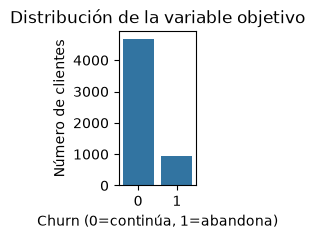

In [156]:
#Grafico de barras
fig, ax = plt.subplots(figsize=(1, 2))
ax = sns.countplot(data=df, x="Churn")
ax.set_title("Distribución de la variable objetivo")
ax.set_xlabel("Churn (0=continúa, 1=abandona)")
ax.set_ylabel("Número de clientes")

plt.show()

De los 5630 cientes, **4682 (83.2%)** son clientes que permaneces, por otro lado, *948 (16.8%)* son clientes que avandonan la compañia. Se observa cierto desbalance en las clases lo cual podría afectar las predicciones y se tiene que tomar en cuenta ya que el modelo podría aprender de la clases que no abandona al ser la que más aparece y daría como consecuencia un accuracy alto sin que esto realmente signifique que esta aprendiendo relamente. 

De cara en las métricas seleccionadas no podemos considerar solo accuracy, tenemos que considerar métricas como `recall`, `F1`, `precision`, `ROC-AUC`. Además que una `división estratificada` de los datos. 

#### 2.3 Distribución de las varibales numéricas 
Observamos la distribución de las variables numéricas en busqueda de sesgos, y presencia de outliers

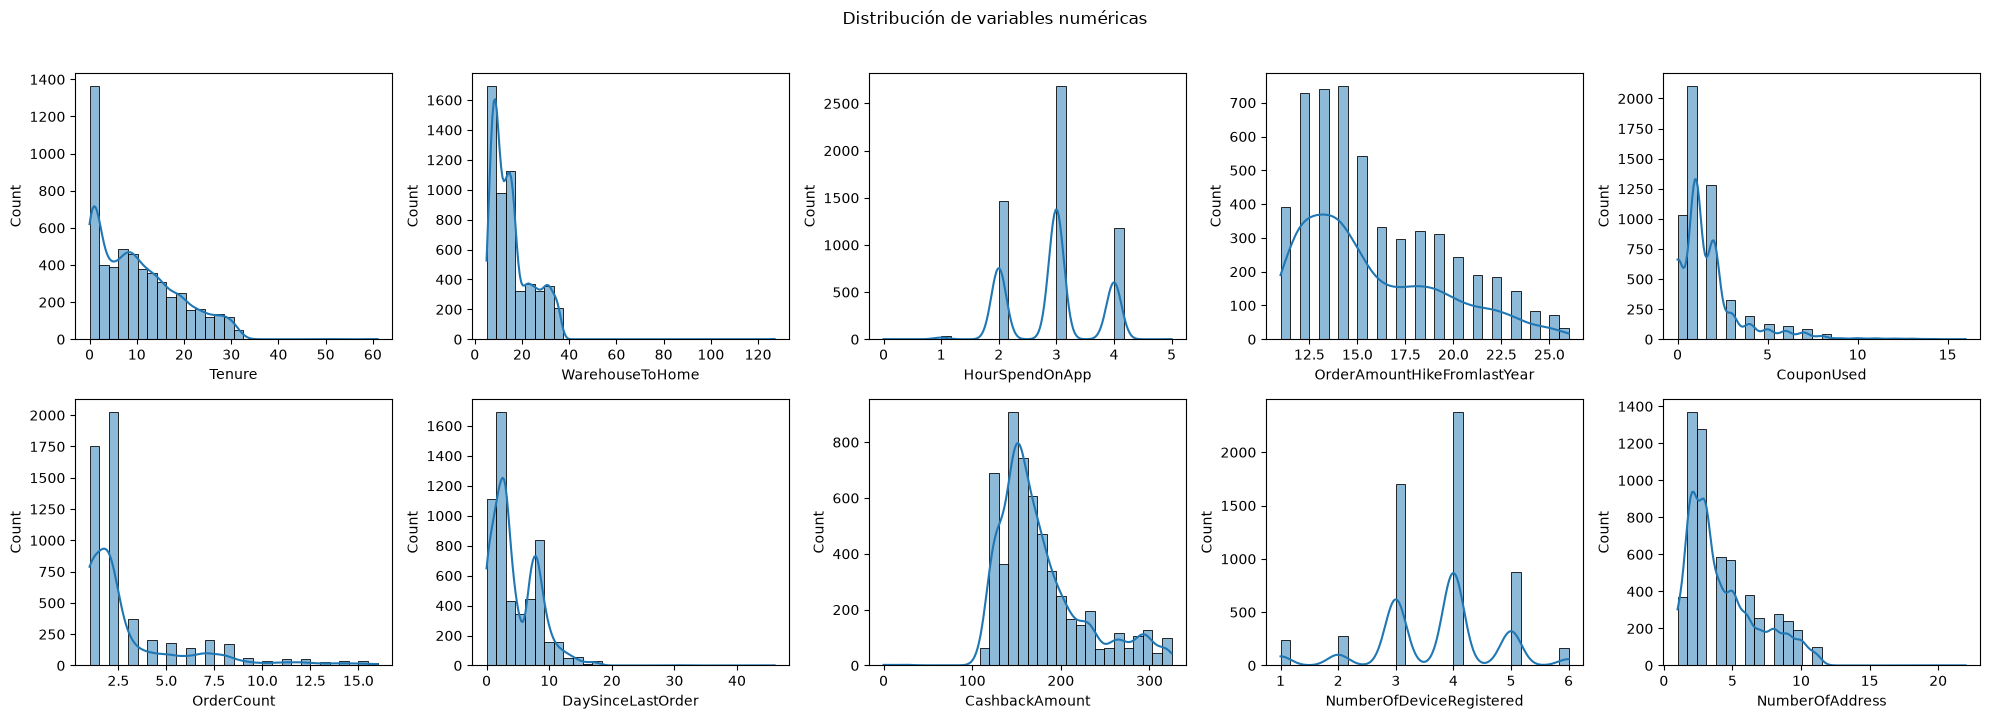

In [157]:
#Histograas con seaborn para las variables numéricas
fig, axes = plt.subplots(2, 5, figsize=(20,7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.histplot(df[col], bins=30, kde=True, ax=ax)
    ax.set_title = col
    
plt.suptitle("Distribución de variables numéricas", y=1.02)
plt.tight_layout()
plt.show()

Aqui confirmamos algunos puntos mencionados previamente. 

* **Sesgadas a la derecha:** `Tenure`, `WarehouseToHome`, `CouponUsed`, `OrderCount`, `DaySinceLastOrder`, `CashbackAmount` y `NumberOfAddress`. La mayoría de los clientes tiene valores bajos y una minoría tiene valores muy altos.
* **`Tenure`** Tiene un pico cerca de 0, lo que podría significar que la mayoria de los clientes son muy recientes.
* **`CouponUsed` y `OrderCount`** se concentran en 1 y 2, con una cola larga hasta 16, lo que representa que la gran mayoria de clientes ha realizado pocos pedidos y muy pocos de ellos ha echo uso de algún cupon. 
* **Variables casi discretas:** `HourSpendOnApp` toma básicamente los valores 2, 3 y 4 (con 3 como el más común), y `NumberOfDeviceRegistered` se concentra en 3, 4 y 5. Se tratan como numéricas, pero no son continuas.
* **`WarehouseToHome` y `DaySinceLastOrder`** confimamos lo que visualizamos con el análisis descriptivo, la presencia de **outliers**
* **`CashbackAmount`** se concentra alrededor de 150 y tiene una cola hacia valores altos (hasta ≈325).

### Varibales categóricas
Frecuencia de las categorias mediante gráficas, se buscan aquellas que predominan

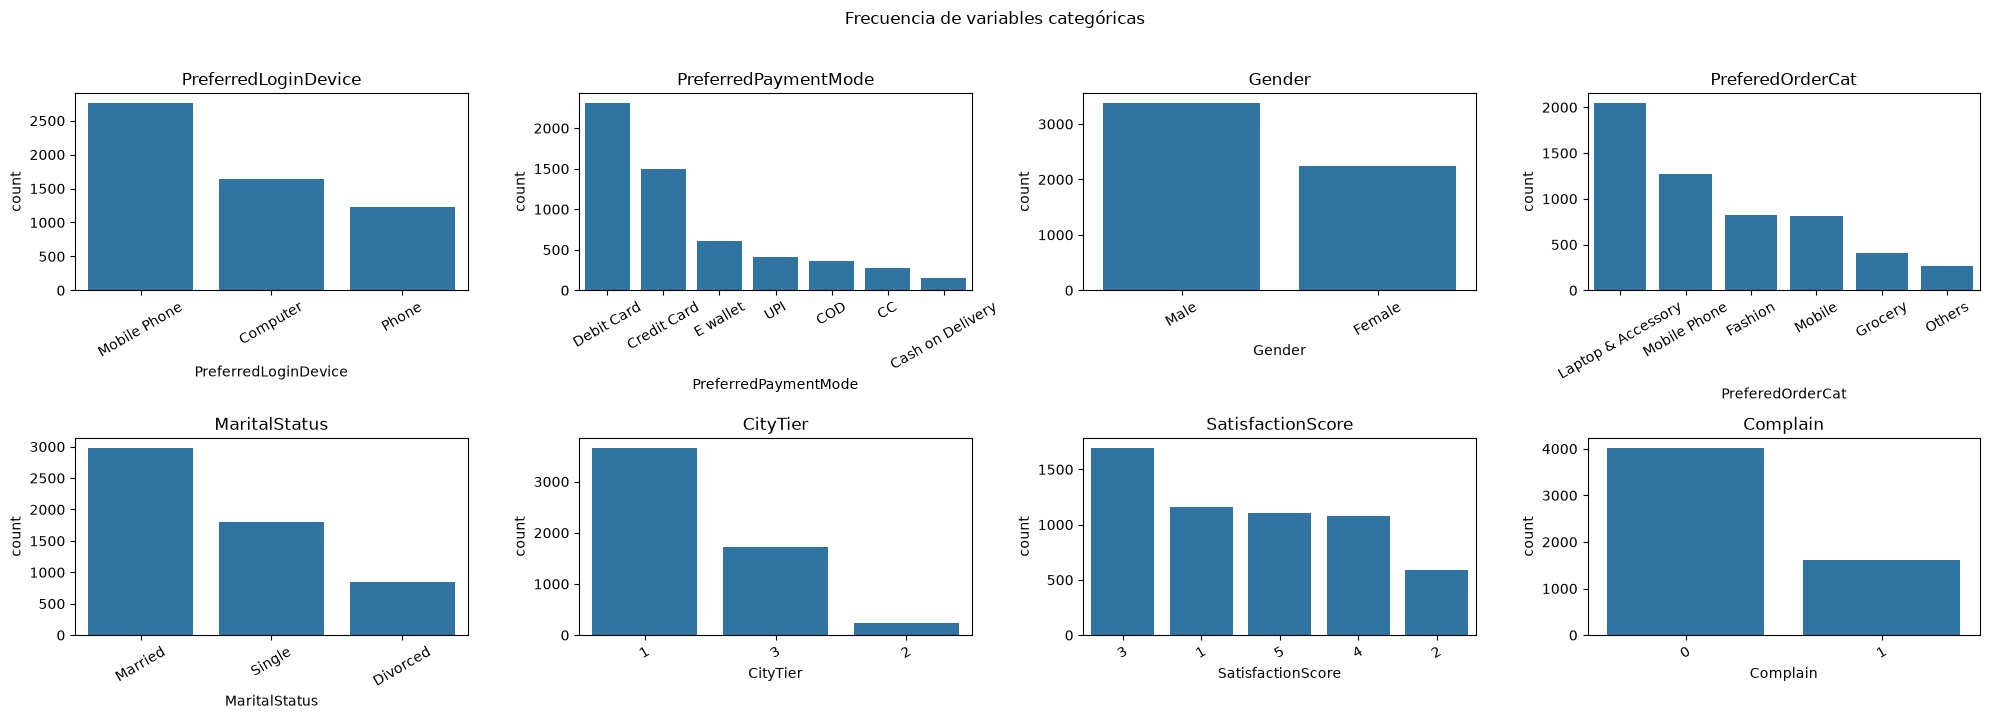

In [158]:
fig, axes = plt.subplots(2, 4, figsize=(20,7))
for ax, col in zip(axes.flatten(), cat_cols):
    categories = df[col].value_counts().index
    sns.countplot(data=df, x= col, order= categories, ax= ax)
    ax.set_title(col)
    ax.tick_params(axis = "x", rotation=30)
plt.suptitle("Frecuencia de variables categóricas", y=1.02)
plt.tight_layout()
plt.show()

* **Duplicados confirmados.** Las gráficas muestran por separado "Mobile Phone" y "Phone" (`PreferredLoginDevice`), "Credit Card" y "CC", "Cash on Delivery" y "COD" (`PreferredPaymentMode`), y "Mobile Phone" y "Mobile" (`PreferedOrderCat`). Son etiquetas distintas para posibles categorías iguales y posteriormente las unificaremos.
* **Desbalance entre categorías.** `CityTier` predomina el nivel 1 (3,650 clientes) y el nivel 2 tiene muy pocos (240). `Gender` tiene más hombres que mujeres. `MaritalStatus` tiene en su gran mayoria casados.
* **Perfil general.** Los clientes prefieren pagar con tarjeta de débito, entran sobre todo desde el celular y compran sobre todo "Laptop & Accessory".
* **Quejas.** Aproximadamente una cuarta parte presentó una queja en el último mes.

### 2.5 Relación de las variables con la variable objetivo

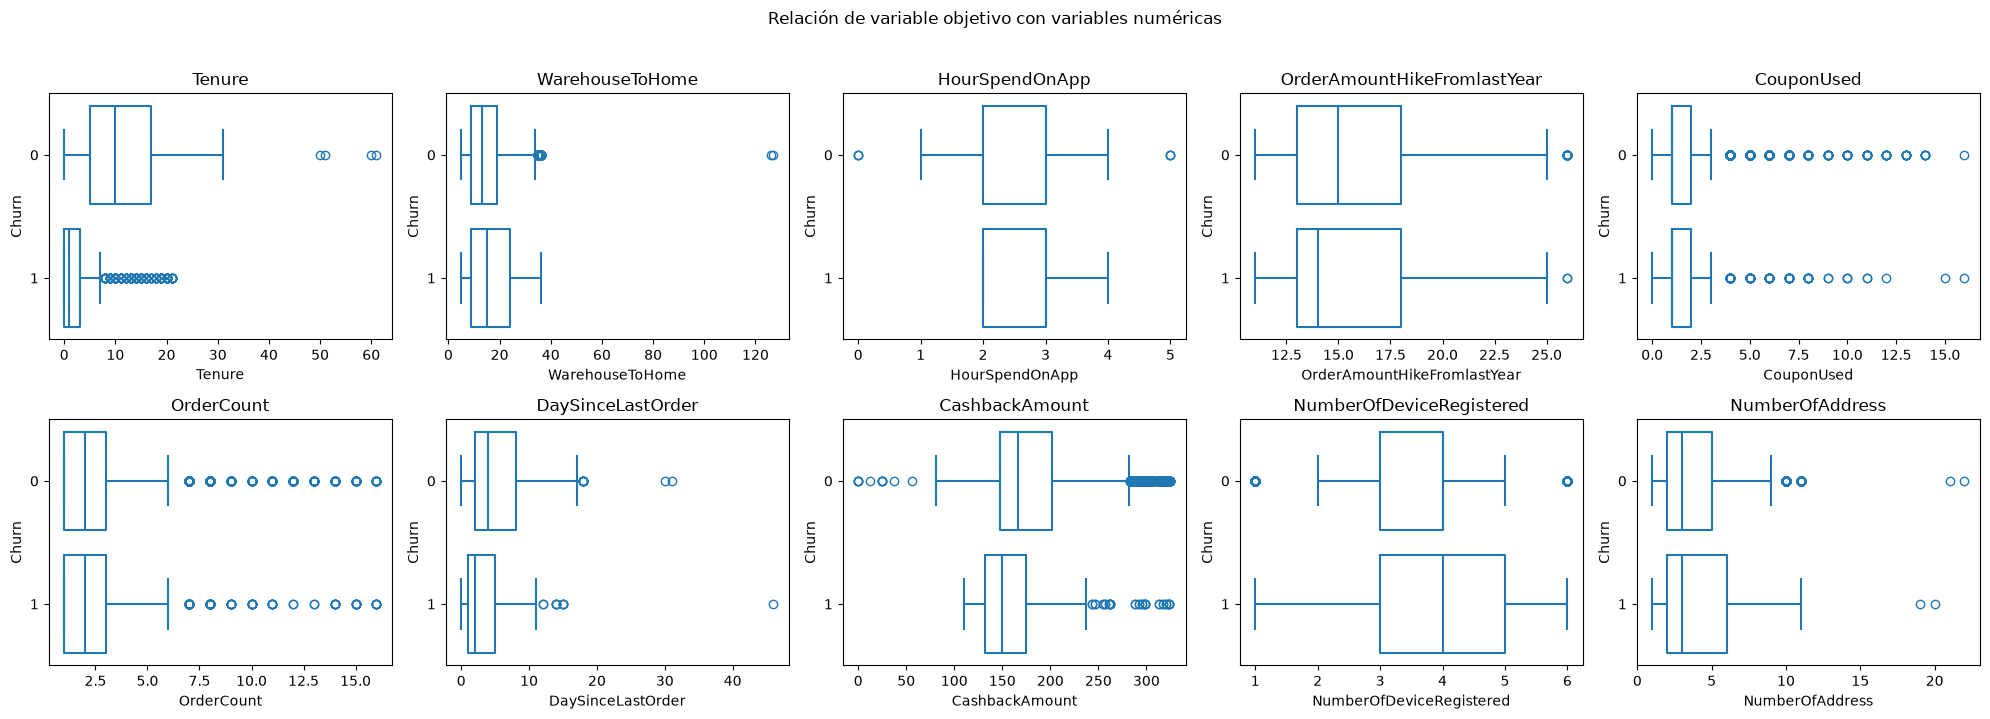

In [159]:
fig, axes = plt.subplots(2, 5, figsize=(20,7))
for ax, col in zip(axes.flatten(), num_cols):
    sns.boxplot(data=df, x=col, y="Churn", fill=False, ax=ax, orient="h")
    ax.set_title(col)
    ax.set_ylabel("Churn")

plt.suptitle("Relación de variable objetivo con variables numéricas", y=1.02)
plt.tight_layout()
plt.show()


* **`Tenure` es la variable que más diferencía a las dos clases.** Los clientes que abandonan son los que menor antiguedad tienen. 
* **`DaySinceLastOrder` y `CashbackAmount`** tienden a ser más bajos en quienes abandonan, lo que podria traducirse a que compraron recientemente pero recibieron menos cashback.
* **`NumberOfDeviceRegistered` y `NumberOfAddress`** Los clientes que abandonan tiene a registrar por un poco más dispositivos y direcciones en comparación de los que no.
* **`HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed` y `OrderCount`** casi no muestran diferencias entre ambos grupos.
* **Valores extremos aislados.** Destacan `WarehouseToHome ≈ 127`, `DaySinceLastOrder ≈ 46` y `NumberOfAddress ≈ 22`. A diferencia de los puntos de `CouponUsed`, `OrderCount` o `CashbackAmount`, que forman colas continuas posiblemente sea un comportamiento real


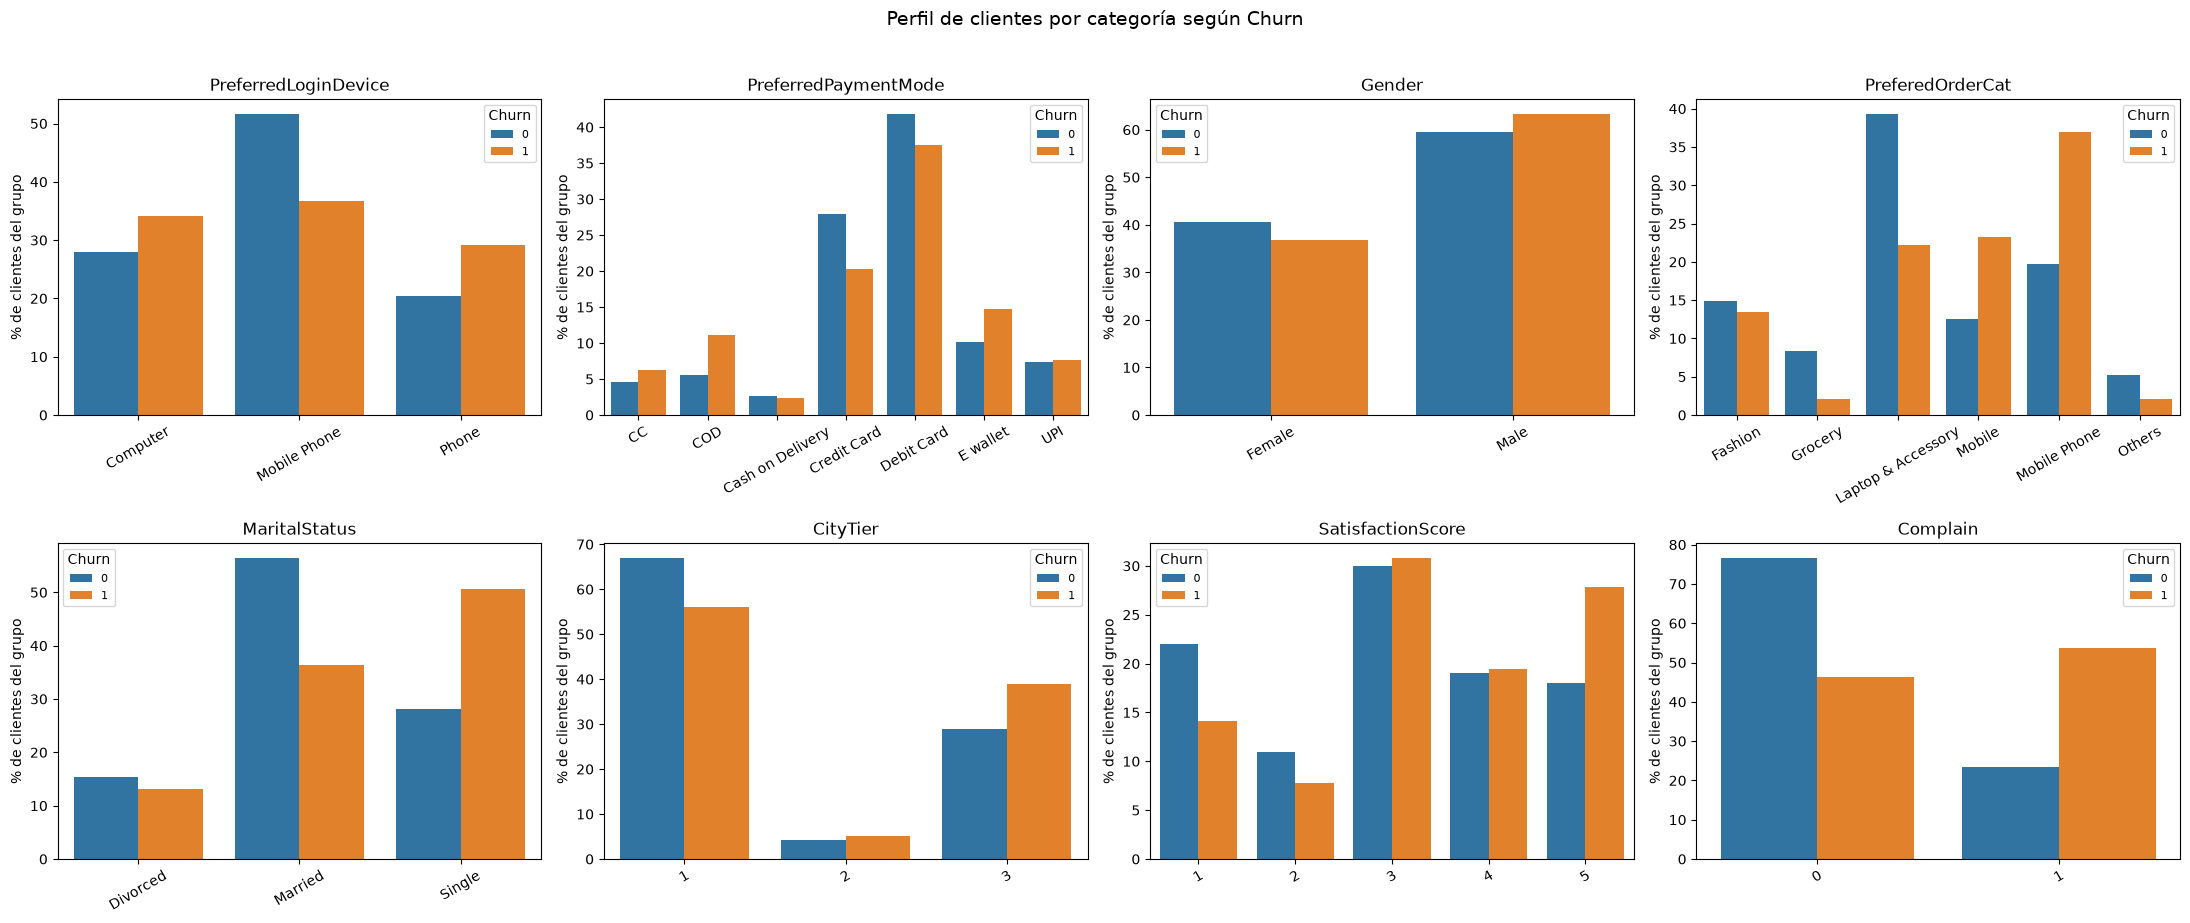

In [160]:
fig, axes = plt.subplots(2, 4, figsize=(22, 9))

for ax, col in zip(axes.flatten(), cat_cols):
    # % de cada categoría dentro de cada grupo de Churn
    cat = (
        pd.crosstab(df[col], df["Churn"], normalize="columns")
        .mul(100)
        .reset_index()
        .melt(id_vars=col, var_name="Churn", value_name="% de clientes")
    )
    cat[col] = cat[col].astype(str)

    sns.barplot(data=cat, x=col, y="% de clientes", hue="Churn", ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
    ax.set_ylabel("% de clientes del grupo")
    ax.tick_params(axis="x", rotation=30)
    ax.legend(title="Churn", fontsize=8)

plt.suptitle("Perfil de clientes por categoría según Churn", y=1.02, fontsize=14)
plt.tight_layout()
plt.show()

Las barras color azul corresponden a los clientes que permanecen y naranja a quienes abandonan. Así podemos comparar qué categorías tienen mayor presencia en cada grupo.

* **`Complain`:** Poco más del 50% de quienes abandonan presentó una queja, en comparación con el 25% de quienes permanecen.
* **`MaritalStatus`:** Son más la cantidad de solteros que tieden a abandonar, por otro lado los casados son aquellos que permanecen.
* **`PreferedOrderCat`:** Mobile Phone y Mobile son categorias de compra de quienes tienden a abondanar la caompañia, mientras que Laptop & Accessory son las categorias preferidas de aquellos clientes que permanecem.
* **`CityTier`:** el nivel 3 tiene mayor peso entre quienes abandonan, mientras que el nivel 1 predomina entre quienes permanecen.
* **`PreferredPaymentMode`:** COD y E wallet son los metodos preferidos de pago de aquellos que abandonan, mientras que "Credit Card" suele ser el favorito de quienes permanecen.

**Diferencias pequeñas:** `Gender`, `UPI`, `Cash on Delivery`, `Fashion`, `Divorced` y los puntajes de satisfacción 3 y 4 muestran diferencias poco marcadas entre ambos grupos.

**Hallazgos para la limpieza:** algunas categorías que parecen duplicadas presentan comportamientos distintos, como `CC` y `Credit Card`, o `COD` y `Cash on Delivery`. Por ello, conviene revisar si realmente representan lo mismo antes de unificarlas. Identificamos que los puntajes de satisfacción 1 y 2 son menos seleccionados por las personas que abandonan, mientras que el puntaje 5 es el que más se selecciona. Este comportamineto no corresponde a lo que se esperaría, por lo que podría significar una mala interpretación del score.


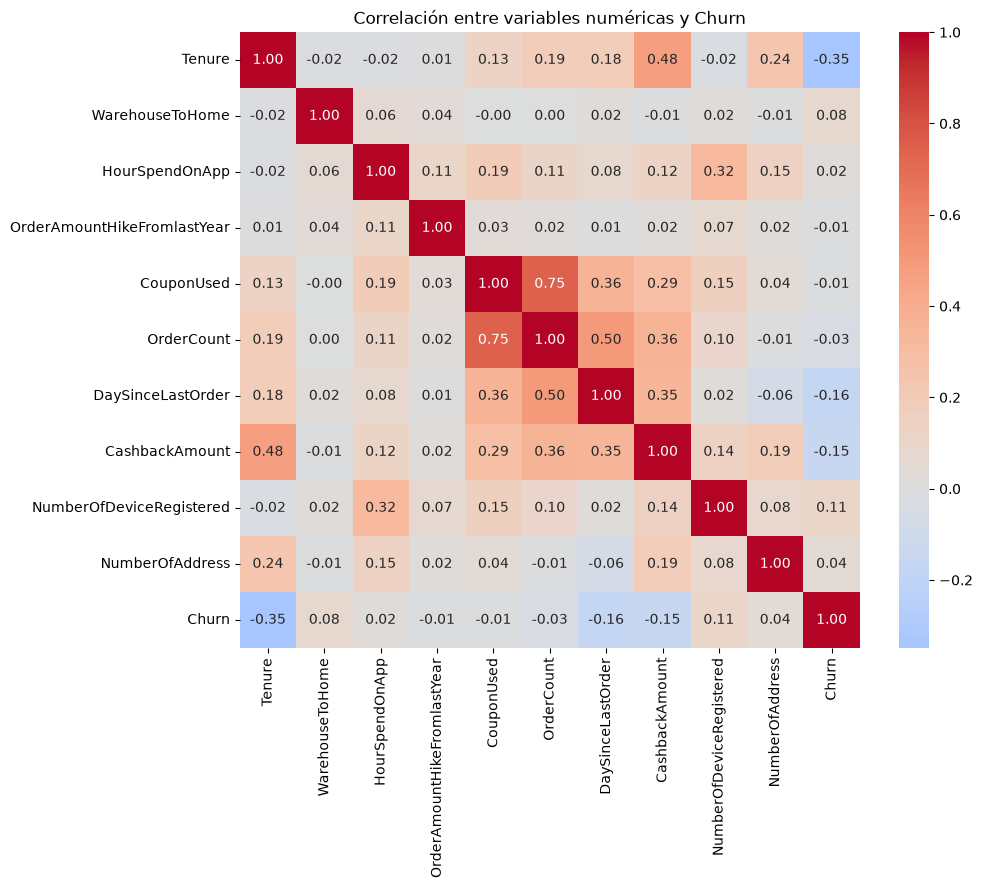

Tenure                        -0.349
DaySinceLastOrder             -0.161
CashbackAmount                -0.154
NumberOfDeviceRegistered       0.108
WarehouseToHome                0.077
NumberOfAddress                0.044
OrderCount                    -0.029
HourSpendOnApp                 0.019
OrderAmountHikeFromlastYear   -0.010
CouponUsed                    -0.008
Name: Churn, dtype: float64

In [161]:
# Matriz de correlación entre variables numéricas y Churn
corr = df[num_cols + ["Churn"]].corr()

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlación entre variables numéricas y Churn")
plt.show()

# Correlación de cada variable con Churn, ordenada
corr["Churn"].drop("Churn").sort_values(key=abs, ascending=False).round(3)

* **Relación con Churn.** La correlación más fuerte es con `Tenure` (**-0.35**), a mayor antigüedad, menos abandono. Le siguen `DaySinceLastOrder` (−0.16), `CashbackAmount` (−0.15) y `NumberOfDeviceRegistered` (+0.11). 
* **Colinealidad entre variables explicativas.** `CouponUsed` y `OrderCount` están muy correlacionadas (**0.75**), lo que podría significar que los clientes que realizan más pedidos podrían hacer hecho uso de más cupones. También hay relación moderada entre `Tenure` y `CashbackAmount` (0.48), aquellos clientes con mayor antiguedad son aquellos que recibieron mayor cashback y entre `OrderCount` y `DaySinceLastOrder` (0.50) donde los clientes con mayor numero de ordenes son los que probablememente no han realizado pedidos recientemente. Esto importa para el modelo base porque regresión logística es sensible a la colinealidad.

### 2.6 Detección de valores atípicos

In [162]:
filas=[]
for col in num_cols:
    serie = df[col].dropna()
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    mask = (serie < lim_inf) | (serie > lim_sup)
    filas.append({
        "Variable": col,
        "Q1": q1, "Q3": q3,
        "Límite inf.": lim_inf, "Límite sup.": lim_sup,
        "N atípicos": int(mask.sum()),
        "% atípicos": round(mask.mean() * 100, 2),
        "Mín. observado": serie.min(),
        "Máx. observado": serie.max(),
    })
display(pd.DataFrame(filas).set_index("Variable"))

,Q1,Q3,Límite inf.,Límite sup.,N atípicos,% atípicos,Mín. observado,Máx. observado
Variable,,,,,,,,
Tenure,2.00,16.0000,-19.00000,37.00000,4,0.07,0.0,61.00
WarehouseToHome,9.00,20.0000,-7.50000,36.50000,2,0.04,5.0,127.00
HourSpendOnApp,2.00,3.0000,0.50000,4.50000,6,0.11,0.0,5.00
OrderAmountHikeFromlastYear,13.00,18.0000,5.50000,25.50000,33,0.62,11.0,26.00
CouponUsed,1.00,2.0000,-0.50000,3.50000,629,11.70,0.0,16.00
OrderCount,1.00,3.0000,-2.00000,6.00000,703,13.09,1.0,16.00
DaySinceLastOrder,2.00,7.0000,-5.50000,14.50000,62,1.16,0.0,46.00
CashbackAmount,145.77,196.3925,69.83625,272.32625,438,7.78,0.0,324.99
NumberOfDeviceRegistered,3.00,4.0000,1.50000,5.50000,397,7.05,1.0,6.00


Para identificar posibles valores atípicos, utilizamos el rango intercuartílico (IQR), que permite detectar los valores que quedan por debajo del límite inferior o por encima del límite superior. Sin embargo, que un valor quede fuera de estos límites no significa necesariamente que sea un error. Por ello, agrupamos los resultados en tres categorías según qué tan alejados están del resto de los datos y si su valor parece razonable.

**1. Pocos registros con valores muy alejados del resto, que conviene revisar.**

* `WarehouseToHome`: Se identificaron 2 registros (0.04%) con valores de hasta 127, cuando el límite superior es 36.5 y la mayoría de los datos se concentra por debajo de 36. Es el caso que genera mayor sospecha de un posible error de captura, ya que los valores encontrados son aproximadamente tres veces mayores que el límite identificado.

* `Tenure`: Hay 4 registros (0.07%) con valores de 50, 51, 60 y 61, mientras que el resto de los datos llega hasta 31. Aunque están bastante alejados del resto, corresponden a clientes que permanecen activos y donde las demás variables presentan valores normales. Ppodrían representar clientes con mayor antigüedad y no necesariamente errores.

* `NumberOfAddress`: Se encontraron 4 registros (0.07%) con entre 19 y 22 direcciones, por encima del límite superior de 12. Son casos poco comunes que vale la pena revisar, aunque no se puede descartar que sean válidos.

* `DaySinceLastOrder`: Se identificaron 62 registros (1.16%) por encima de 14.5 días. En general, los valores siguen una tendencia gradual que podría corresponder a clientes que llevan más tiempo sin realizar pedidos. Sin embargo, el valor máximo de 46 días destaca por estar más alejado del resto y podría revisarse con mayor detalle.

**2. Valores identificados por el IQR que no necesariamente representan un problema.**

* `HourSpendOnApp` y `NumberOfDeviceRegistered`: Se marcaron 6 y 397 registros (7.05%), respectivamente. En ambas variables, el IQR es de apenas una unidad, por lo que pequeñas diferencias hacen que algunos valores queden fuera de los límites. Sin embargo, los valores identificados, como 0 y 5 horas o entre 1 y 6 dispositivos.

* `OrderAmountHikeFromlastYear`: Se encontraron 33 registros (0.62%) con un valor de 26, una diferencia muy pequeña en comparación con el límite superior de 25.5. Debido a que la diferencia es mínima y el valor se encuentra dentro del rango esperado de la variable, no parece necesario tratar estos registros como errores.

**3. Variables con muchos valores marcados debido a una distribución de cola larga.**

* `CouponUsed` y `OrderCount`: Se identificaron 629 registros (11.7%) y 703 registros (13.1%), respectivamente. Como el IQR es de solo una unidad para `CouponUsed` y dos para `OrderCount`, el método marca como atípicos a los clientes que utilizan 4 o más cupones o realizan 7 o más pedidos. Sin embargo, ambas variables presentan una cola larga, con valores de hasta 16, lo que puede reflejar diferencias reales en el comportamiento de los clientes. 

* `CashbackAmount`: Se marcaron 438 registros (7.8%), con valores de hasta aproximadamente 325. La variable también presenta una cola larga y está relacionada con la antigüedad y la cantidad de pedidos, por lo que estos valores podrían representar a clientes con mayor actividad o consumo, en lugar de errores.


Finalmente observamos que no todos los valores identificados mediante el IQR deben tratarse como errores. Los casos que requieren mayor atención son los del primer grupo, especialmente `WarehouseToHome`, cuyo valor máximo de 127 resulta considerablemente alejado del resto. En las demás variables podría ser parte de su comportamiento o a las características de su distribución. 


### Conclusiones del EDA

**1. Distribución de la variable objetivo**

La mayoría de los clientes permanece con un total de 4,682 (83.2%), mientras que 948 (16.8%) abandonan. Como los grupos no están equilibrados, dividiremos los datos de forma estratificada para conservar sus proporciones. Además, evaluaremos el modelo con métricas como *recall*, *precision*, *F1* y *ROC-AUC*, y no únicamente con *accuracy*.

**2. ¿Qué distingue a los clientes que abandonan?**

* **Antigüedad (`Tenure`):** es la variable que muestra la relación más clara con el abandono (correlación de −0.35). Quienes abandonan suelen tener valores pequeños en esta variable representando menor antigüedad, mientras que entre quienes permanecen la mediana es de aproximadamente 10. Esta diferencia se mantiene en las distintas categorías analizadas.
* **Quejas (`Complain`):** alrededor del 53% de quienes abandonan presentó una queja, frente al 23% de quienes permanecen. Es una de las diferencias más marcadas entre ambos grupos.
* **Perfil del cliente:** los solteros, los clientes de ciudades de nivel 3, quienes pagan con COD o e-wallet y quienes prefieren las categorías "Mobile" y "Mobile Phone" tienen mayor presencia entre quienes abandonan. En cambio, "Laptop & Accessory", "Grocery" y "Others" son preferidas por quienes permanecen.
* **Otras variables numéricas:** `DaySinceLastOrder` (−0.16), `CashbackAmount` (−0.15) y `NumberOfDeviceRegistered` (+0.11) presentan relaciones débiles con el abandono. Variables como `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed` y `OrderCount` muestran poca diferencia entre los grupos.
* **Variables con poca diferencia:** `Gender` y categorías como UPI, "Cash on Delivery", "Fashion", "Divorced" y los puntajes de satisfacción 3 y 4 aportan pocas diferencias visibles entre quienes permanecen y quienes abandonan.
* **Satisfacción:** los resultados llaman la atención porque el puntaje 5 son más seleccionados entre quienes abandonan, mientras que los puntajes 1 y 2 son los menos. Esto indica que las calificaciones no siguen el comportamiento que esperaríamos y que vale la pena revisar qué otros factores podrían influir en el abandono. 

**3. Problemas de calidad de datos por atender**

* **Valores faltantes:** siete variables tienen entre 251 y 307 registros vacíos, aproximadamente el 5% cada una: `Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount` y `DaySinceLastOrder`. Será necesario definir cómo tratar estos valores antes de entrenar el modelo.
* **Categorías similares o duplicadas:** se encontraron etiquetas como "Mobile Phone" y "Phone" en `PreferredLoginDevice`; "CC" y "Credit Card", así como "COD" y "Cash on Delivery", en `PreferredPaymentMode` y "Mobile" y "Mobile Phone" en `PreferedOrderCat`. Antes de unificarlas, revisaremos si realmente representan lo mismo, ya que algunas muestran comportamientos distintos frente al abandono.
* **Valores atípicos:** los casos que más conviene revisar son `WarehouseToHome` = 127 (2 registros), `Tenure` entre 50 y 61 (4 registros), `NumberOfAddress` entre 19 y 22 (4 registros) y el valor máximo de `DaySinceLastOrder` (46). 
* **Identificadores y tipos de datos:** `CustomerID` se excluirá del modelo porque identifica a cada cliente, pero no representa una característica útil para predecir el abandono. También se revisarán los tipos de datos: `CityTier` se tratará como categórica, aunque esté representada por números, mientras que `Churn` y `Complain` se reconocerán como variables binarias.

**4. Observaciones adicionales**

Se identificaron relaciones entre algunas variables, especialmente entre `CouponUsed` y `OrderCount` (0.75), así como entre `Tenure` y `CashbackAmount` (0.48), y entre `OrderCount` y `DaySinceLastOrder` (0.50). 

En general, las correlaciones con `Churn` son débiles o moderadas, por lo que no esperamos que un modelo sencillo explique por sí solo todo el comportamiento de los clientes. 

Finalmente, las variables categóricas deberán codificarse y los valores faltantes de las variables numéricas deberán tratarse antes del entrenamiento. Estos procesos se ajustarán utilizando únicamente los datos de entrenamiento, para evitar que información del conjunto de prueba influya en el modelo.


### 3. Limpieza de datos

Se revisan los problemas de calidad de datos identificados en el EDA. Siguiendo los pasos a continuación.

1. Duplicados
2. Tipos de datos
3. Categorías redundantes
4. Valores atípicos
5. Valores faltantes

#### 3.1 Valores duplicados

Se identifican filas completamente idénticas y CustomerID repetidos

In [163]:
#Creamos una copia del dataframe original
df_clean = df.copy()

#Identificamos las filas donde todos sus campos son iguales
print("Filas duplicadas:", df_clean.duplicated().sum())

#Identificamos clientes repetidos
print("CustomerID repetidos", df_clean["CustomerID"].duplicated().sum())

#Clientes repetidos excluyendo el CustomerID
print("Duplicados ignorando CustomerID", df_clean.iloc[: , 2:].duplicated().sum())



Filas duplicadas: 0
CustomerID repetidos 0
Duplicados ignorando CustomerID 556


In [164]:
# Variables sin el identificador
cols_sin_id = [c for c in df_clean.columns if c != "CustomerID"]

# Filas que forman parte de algún grupo de duplicados
mask_dup = df_clean.duplicated(subset=cols_sin_id, keep=False)
print("Filas involucradas en duplicados:", mask_dup.sum())
print("Registros que representan un duplicado:", df_clean.duplicated(subset=cols_sin_id).sum())

# Tamaño de cada grupo de duplicados
tam_grupos = df_clean[mask_dup].groupby(cols_sin_id, dropna=False).size()
print("\nTamaño de los grupos de duplicados:")
print(tam_grupos.value_counts())

# Proporción de churn: duplicados frente al resto del dataset
print("\n% de Churn en filas duplicadas:",
      round(df_clean.loc[mask_dup, "Churn"].mean() * 100, 1))
print("% de Churn en filas no duplicadas:",
      round(df_clean.loc[~mask_dup, "Churn"].mean() * 100, 1))

# Muestra de los duplicados
df_clean[mask_dup].sort_values(cols_sin_id).head(10)

Filas involucradas en duplicados: 1112
Registros que representan un duplicado: 556

Tamaño de los grupos de duplicados:
2    556
Name: count, dtype: int64

% de Churn en filas duplicadas: 19.2
% de Churn en filas no duplicadas: 16.2


,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,PreferedOrderCat,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount
1045,51046,0,0.0,Computer,1,NaN,CC,Male,2.0,3,Mobile,1,Single,3,0,13.0,0.0,1.0,2.0,125.80
2515,52516,0,0.0,Computer,1,NaN,CC,Male,2.0,3,Mobile,1,Single,3,0,13.0,0.0,1.0,2.0,125.80
39,50040,0,0.0,Computer,1,NaN,CC,Male,3.0,4,Mobile,3,Married,2,1,15.0,0.0,1.0,1.0,125.66
1509,51510,0,0.0,Computer,1,NaN,CC,Male,3.0,4,Mobile,3,Married,2,1,15.0,0.0,1.0,1.0,125.66
1192,51193,0,0.0,Computer,1,NaN,Debit Card,Female,2.0,3,Mobile,1,Single,1,1,14.0,1.0,1.0,2.0,123.79
2662,52663,0,0.0,Computer,1,NaN,Debit Card,Female,2.0,3,Mobile,1,Single,1,1,14.0,1.0,1.0,2.0,123.79
1236,51237,0,0.0,Computer,1,NaN,UPI,Male,3.0,1,Mobile,1,Married,1,0,18.0,2.0,7.0,7.0,125.44
2706,52707,0,0.0,Computer,1,NaN,UPI,Male,3.0,1,Mobile,1,Married,1,0,18.0,2.0,7.0,7.0,125.44
87,50088,0,0.0,Computer,3,26.0,Debit Card,Female,2.0,3,Laptop & Accessory,3,Single,2,0,14.0,1.0,1.0,7.0,199.81
1557,51558,0,0.0,Computer,3,26.0,Debit Card,Female,2.0,3,Laptop & Accessory,3,Single,2,0,14.0,1.0,1.0,7.0,199.81


In [165]:
# Verificar que la diferencia de ID entre las dos copias es constante en todos los pares
dup = df_clean[mask_dup].copy()
dup["grupo"] = dup.groupby(cols_sin_id, dropna=False).ngroup()
dif_id = dup.groupby("grupo")["CustomerID"].agg(lambda x: x.max() - x.min())
print(dif_id.value_counts())

CustomerID
1470    546
1438      2
1460      2
1346      2
1357      2
1384      2
Name: count, dtype: int64


In [166]:
# Pares cuya diferencia de ID no es 1470
grupos_raros = dif_id[dif_id != 1470].index
display(dups[dups["grupo"].isin(grupos_raros)].sort_values(["grupo", "CustomerID"]))

,CustomerID,Churn,Tenure,PreferredLoginDevice,CityTier,WarehouseToHome,PreferredPaymentMode,Gender,HourSpendOnApp,NumberOfDeviceRegistered,...,SatisfactionScore,MaritalStatus,NumberOfAddress,Complain,OrderAmountHikeFromlastYear,CouponUsed,OrderCount,DaySinceLastOrder,CashbackAmount,grupo
18,50019,1,0.0,Computer,1,13.0,Debit Card,Male,3.0,5,...,3,Single,2,1,24.0,1.0,1.0,6.0,160.74,450
1456,51457,1,0.0,Computer,1,13.0,Debit Card,Male,3.0,5,...,3,Single,2,1,24.0,1.0,1.0,6.0,160.74,450
25,50026,1,0.0,Phone,1,15.0,Credit Card,Female,2.0,3,...,5,Single,8,0,22.0,1.0,1.0,4.0,142.00,465
1485,51486,1,0.0,Phone,1,15.0,Credit Card,Female,2.0,3,...,5,Single,8,0,22.0,1.0,1.0,4.0,142.00,465
2833,52834,1,1.0,Computer,1,14.0,Debit Card,Male,4.0,6,...,3,Single,3,1,25.0,2.0,2.0,7.0,185.74,481
4271,54272,1,1.0,Computer,1,14.0,Debit Card,Male,4.0,6,...,3,Single,3,1,25.0,2.0,2.0,7.0,185.74,481
2840,52841,1,1.0,Mobile Phone,1,16.0,Credit Card,Female,3.0,4,...,5,Single,9,0,23.0,2.0,2.0,5.0,167.00,496
4300,54301,1,1.0,Mobile Phone,1,16.0,Credit Card,Female,3.0,4,...,5,Single,9,0,23.0,2.0,2.0,5.0,167.00,496
2816,52817,1,1.0,Phone,1,9.0,UPI,Male,4.0,5,...,3,Single,8,1,16.0,1.0,2.0,1.0,145.90,507
4162,54163,1,1.0,Phone,1,9.0,UPI,Male,4.0,5,...,3,Single,8,1,16.0,1.0,2.0,1.0,145.90,507


**Resultado y decisión**

No hay filas completamente duplicadas ni `CustomerID` repetidos. Sin embargo, al comparar todas las variables **excepto el identificador**, aparecen **556 pares de registros idénticos** (1,112 filas; todos los grupos son de 2 registros). Los dos registros de cada par repiten los valores de las 19 variables, incluyendo `CashbackAmount` (con dos decimales) y los mismos valores faltantes. Además, los identificadores de cada tienen una diferencia en 546 de los 556 pares de 1,470, y en los 10 restantes está entre 1,346 y 1,460. Esto nos indica que corresponden a registros copiados con un ID nuevo y no a clientes distintos con perfiles coincidentes.

**Decisión:** se eliminan las 556 copias y se conserva la primera aparición de cada perfil (la de menor `CustomerID`). Mantenerlas sesgaría el entrenamiento y, si una copia quedara en el conjunto de entrenamiento y la otra en el de prueba, inflaría artificialmente las métricas por fuga de información.

In [167]:
# Eliminar las copias, conservando la primera aparición (la de menor CustomerID)
n_antes = len(df_clean)
df_clean = df_clean.drop_duplicates(subset=cols_sin_id, keep="first").reset_index(drop=True)

print(f"Registros antes: {n_antes:,} | después: {len(df_clean):,} | eliminados: {n_antes - len(df_clean)}")

# Balance de la variable objetivo tras la limpieza
print(df_clean["Churn"].value_counts())
print(df_clean["Churn"].value_counts(normalize=True).mul(100).round(1))

Registros antes: 5,630 | después: 5,074 | eliminados: 556
Churn
0    4233
1     841
Name: count, dtype: int64
Churn
0    83.4
1    16.6
Name: proportion, dtype: float64


Tras la eliminación quedan 5,074 registros: 4,233 que permanecen (83.4%) y 841 que abandonan (16.6%). El desbalance de clases prácticamente no cambia respecto al dataset original (83.2% / 16.8%).

### 3.2 Tipos de datos
Ajustamos lo tipos de datos según corresponda

In [168]:
# Tipos de dato actuales
print(df_clean.dtypes)

print("="*50)
# Valores únicos de las variables discretas, para confirmar su naturaleza
for col in ["Churn", "Complain", "CityTier", "SatisfactionScore", "NumberOfDeviceRegistered"]:
    print(f"{col}: {sorted(df_clean[col].dropna().unique())}")

print("="*50)
# Variables numéricas con decimales
cols_enteras = ["Tenure", "WarehouseToHome", "HourSpendOnApp", "OrderAmountHikeFromlastYear",
                "CouponUsed", "OrderCount", "DaySinceLastOrder"]
for col in cols_enteras:
    print(f"{col}: ¿Es Int? {(df_clean[col].dropna() % 1 == 0).all()}")

CustomerID                       int64
Churn                            int64
Tenure                         float64
PreferredLoginDevice               str
CityTier                         int64
WarehouseToHome                float64
PreferredPaymentMode               str
Gender                             str
HourSpendOnApp                 float64
NumberOfDeviceRegistered         int64
PreferedOrderCat                   str
SatisfactionScore                int64
MaritalStatus                      str
NumberOfAddress                  int64
Complain                         int64
OrderAmountHikeFromlastYear    float64
CouponUsed                     float64
OrderCount                     float64
DaySinceLastOrder              float64
CashbackAmount                 float64
dtype: object
Churn: [np.int64(0), np.int64(1)]
Complain: [np.int64(0), np.int64(1)]
CityTier: [np.int64(1), np.int64(2), np.int64(3)]
SatisfactionScore: [np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


### 3.2 Tipos de dato

Se revisó que cada variable tuviera un tipo de dato adecuado a su significado y que sus valores estuvieran dentro de los rangos esperados.

**Verificación de valores.** Las variables discretas contienen valores válidos: `Churn` y `Complain` solo toman valores de 0 y 1; `CityTier`, del 1 al 3; `SatisfactionScore`, del 1 al 5; y `NumberOfDeviceRegistered`, del 1 al 6. No se encontraron valores fuera de estos rangos.

También se observó que las siete variables numéricas que aparecen como `float64` (`Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount` y `DaySinceLastOrder`) contienen valores enteros cuando no están vacías. Se mantienen como decimales porque pandas utiliza este tipo para representar los valores faltantes mediante `NaN`.

**Decisiones sobre los tipos de dato:**

* **`CustomerID`:** al ser un identificador y no aportar información directa para la predicción, se utiliza como índice del DataFrame para conservar la referencia de cada cliente sin incluirlo como variable del modelo.
* **`CityTier`:** se convierte a tipo categórico, ya que representa niveles de ciudad y no una cantidad numérica.
* **`Churn` y `Complain`:** se mantienen como enteros porque son variables binarias que toman valores de 0 y 1.
* **`SatisfactionScore`:** se mantiene como numérica, ya que sus valores representan niveles ordenados de satisfacción del 1 al 5.
* **Variables numéricas con valores faltantes:** se conservan como `float64` para facilitar el tratamiento de los valores ausentes durante el modelado, sin necesidad de cambiar a un tipo entero que admita nulos.
* **Variables de texto:** `PreferredLoginDevice`, `PreferredPaymentMode`, `Gender`, `PreferedOrderCat` y `MaritalStatus` se identifican como variables categóricas y se codificarán en el Paso 4 para utilizarlas en el modelo.


In [169]:
# CustomerID pasa a ser el índice 
if "CustomerID" in df_clean.columns:
    df_clean = df_clean.set_index("CustomerID")

# CityTier es una categoría, no una magnitud
df_clean["CityTier"] = df_clean["CityTier"].astype("category")

print(df_clean.dtypes)

Churn                             int64
Tenure                          float64
PreferredLoginDevice                str
CityTier                       category
WarehouseToHome                 float64
PreferredPaymentMode                str
Gender                              str
HourSpendOnApp                  float64
NumberOfDeviceRegistered          int64
PreferedOrderCat                    str
SatisfactionScore                 int64
MaritalStatus                       str
NumberOfAddress                   int64
Complain                          int64
OrderAmountHikeFromlastYear     float64
CouponUsed                      float64
OrderCount                      float64
DaySinceLastOrder               float64
CashbackAmount                  float64
dtype: object


### 3.3 Categorías redundantes
Con base en el análisis previo donde identidicamos etiquetas distintas que parecen representar la misma categoría. Antes de unificarlas verificamos comparamos su represnetación en función de la variable objetivo.

In [170]:
# Tasa de churn por etiqueta original (sobre datos ya sin duplicados), antes de unificar
for col in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print(f"\n{col}")
    tabla = df_clean.groupby(col)["Churn"].agg(Clientes="count", Churn_pct="mean")
    tabla["Churn_pct"] = (tabla["Churn_pct"] * 100).round(1)
    print(tabla.sort_values("Churn_pct", ascending=False))


PreferredLoginDevice
                      Clientes  Churn_pct
PreferredLoginDevice                     
Phone                     1102       21.1
Computer                  1457       19.6
Mobile Phone              2515       12.9

PreferredPaymentMode
                      Clientes  Churn_pct
PreferredPaymentMode                     
COD                        322       29.2
E wallet                   562       22.8
CC                         248       21.0
Cash on Delivery           135       16.3
UPI                        360       15.6
Debit Card                2099       15.0
Credit Card               1348       12.9

PreferedOrderCat
                    Clientes  Churn_pct
PreferedOrderCat                       
Mobile Phone            1130       26.5
Mobile                   726       26.0
Fashion                  763       16.3
Laptop & Accessory      1847       10.5
Others                   242        7.9
Grocery                  366        4.4


**Resultado y decisión**

Se identificaron cuatro etiquetas que, por su significado, equivalen a otra de la misma variable: "Phone" y "Mobile Phone" (`PreferredLoginDevice`), "CC" y "Credit Card" y "COD" y "Cash on Delivery" (`PreferredPaymentMode`), y "Mobile" y "Mobile Phone" (`PreferedOrderCat`). Antes de unificarlas se comparó el pocentaje que representa churn con los datos ya sin duplicados:

| Variable | Etiqueta | % churn | Etiqueta equivalente | % churn |
|---|---|---|---|---|
| `PreferredLoginDevice` | Phone | 21.1 | Mobile Phone | 12.9 |
| `PreferredPaymentMode` | CC | 21.0 | Credit Card | 12.9 |
| `PreferredPaymentMode` | COD | 29.2 | Cash on Delivery | 16.3 |
| `PreferedOrderCat` | Mobile | 26.0 | Mobile Phone | 26.5 |

En `PreferedOrderCat` las dos etiquetas tienen un churn muy parecido con una diferencia mínimoa de 0.5, por lo que es seguro unificarlos. Por otro lado para `PreferredLoginDevice` y `PreferredPaymentMode`, las etiquetas variantes presentan un churn entre 8 y 13 puntos de diferencia de lo que podría representar sus equivalentes, y esta diferencia persiste tras eliminar los duplicados.

**Decisión:** se unifican las cuatro, hacia la etiqueta más descriptiva. Se justifica porque cada par designa la misma categoría por su significado y porque un cliente nuevo se registraría bajo una sola convención, por lo que un modelo que aprendiera la diferencia entre etiquetas estaría usando algo que probablemente no se repetirá en producción. 

In [171]:
# Unificamos etiquetas equivalentes
df_clean["PreferredLoginDevice"] = df_clean["PreferredLoginDevice"].replace(
    {"Phone": "Mobile Phone"})
df_clean["PreferredPaymentMode"] = df_clean["PreferredPaymentMode"].replace(
    {"CC": "Credit Card", 
    "COD": "Cash on Delivery"}
)
df_clean["PreferedOrderCat"] = df_clean["PreferedOrderCat"].replace(
    {"Mobile": "Mobile Phone"})

# Verificar el resultado
for col in ["PreferredLoginDevice", "PreferredPaymentMode", "PreferedOrderCat"]:
    print(f"\n{col}")
    print(df_clean[col].value_counts())


PreferredLoginDevice
PreferredLoginDevice
Mobile Phone    3617
Computer        1457
Name: count, dtype: int64

PreferredPaymentMode
PreferredPaymentMode
Debit Card          2099
Credit Card         1596
E wallet             562
Cash on Delivery     457
UPI                  360
Name: count, dtype: int64

PreferedOrderCat
PreferedOrderCat
Mobile Phone          1856
Laptop & Accessory    1847
Fashion                763
Grocery                366
Others                 242
Name: count, dtype: int64


### 3.4 Valores atípicos

En el EDA identificamos valores atípicos a través del IQR, un valor es atípico si queda fuera de [Q1 − 1.5·IQR, Q3 + 1.5·IQR]. Aquí recalculámos los valores, porque la eliminación de los duplicados puede modificarlo.

**Criterio de decisión**. Que un valor sea atípico no significa que esté mal. Si parece un error de captura, se corrige o se toma como un dato faltante. Si el valor es posible y refleja el comportamiento de un cliente, se conserva, aunque se aleje del resto de los datos. Así evitamos eliminar registros que pueden aportar información al análisis.

Se revisan además los valores iguales a cero en `CashbackAmount` y `HourSpendOnApp`, que podrían ser registros faltantes disfrazados.

In [172]:
# Cuartiles y límites del IQR para todas las variables numéricas
q1 = df_clean[num_cols].quantile(0.25)
q3 = df_clean[num_cols].quantile(0.75)
iqr = q3 - q1
lim_inf = q1 - 1.5 * iqr
lim_sup = q3 + 1.5 * iqr

# Valores fuera de los límites, exceptuando los NaN
es_atipico = (df_clean[num_cols] < lim_inf) | (df_clean[num_cols] > lim_sup)

# Tabla resumen
tabla_atipicos = pd.DataFrame({
    "Q1": q1, "Q3": q3,
    "Límite inf.": lim_inf, "Límite sup.": lim_sup,
    "N atípicos": es_atipico.sum(),
    "% atípicos": (es_atipico.sum() / df_clean[num_cols].notna().sum() * 100).round(2),
    "Mín.": df_clean[num_cols].min(),
    "Máx.": df_clean[num_cols].max(),
})
display(tabla_atipicos.sort_values("% atípicos", ascending=False))

# Registros de WarehouseToHome por encima del límite superior
print("\nWarehouseToHome por encima del límite:")
display(df_clean.loc[df_clean["WarehouseToHome"] > lim_sup["WarehouseToHome"],
                     ["WarehouseToHome", "Churn", "Tenure", "CityTier"]])

# Valores en cero
print(f"\nCashbackAmount por debajo del límite inferior ({lim_inf['CashbackAmount']:.1f}):",
      (df_clean["CashbackAmount"] < lim_inf["CashbackAmount"]).sum())
print("HourSpendOnApp igual a 0:", (df_clean["HourSpendOnApp"] == 0).sum())

,Q1,Q3,Límite inf.,Límite sup.,N atípicos,% atípicos,Mín.,Máx.
OrderCount,1.000,3.00,-2.0000,6.0000,673,13.93,1.0,16.00
CouponUsed,1.000,2.00,-0.5000,3.5000,610,12.54,0.0,16.00
CashbackAmount,145.915,197.95,67.8625,276.0025,382,7.53,0.0,324.99
NumberOfDeviceRegistered,3.000,4.00,1.5000,5.5000,363,7.15,1.0,6.00
DaySinceLastOrder,2.000,7.00,-5.5000,14.5000,57,1.19,0.0,46.00
OrderAmountHikeFromlastYear,13.000,18.00,5.5000,25.5000,29,0.60,11.0,26.00
HourSpendOnApp,2.000,3.00,0.5000,4.5000,6,0.12,0.0,5.00
Tenure,2.000,16.00,-19.0000,37.0000,4,0.08,0.0,61.00
NumberOfAddress,2.000,6.00,-4.0000,12.0000,4,0.08,1.0,22.00
WarehouseToHome,9.000,20.00,-7.5000,36.5000,2,0.04,5.0,127.00



WarehouseToHome por encima del límite:


,WarehouseToHome,Churn,Tenure,CityTier
CustomerID,,,,
51310,126.0,0,25.0,3
54125,127.0,0,26.0,3



CashbackAmount por debajo del límite inferior (67.9): 11
HourSpendOnApp igual a 0: 3


Si comparamos la tabla previa a la limpieza identificamos que los cuartiles de las variables enteras no cambian y solo se desplazan ligeramente los de `CashbackAmount` (Q3 pasa de 196.4 a 198.0 y el límite superior de 272.3 a 276.0), lo que reduce sus atípicos de 438 a 382. Los casos extremos de `Tenure`, `NumberOfAddress` y `WarehouseToHome` se mantienen sin cambios, lo que nos indica que dichos valores no se encontraban en los valores duplicados.

El caso que más nos interesa es el de aquellos registros alejados del resto (`WarehouseToHome`, `Tenure`, `NumberOfAddress`), con 2, 4 y 4 registros. El caso más llamativo es `WarehouseToHome`, con un máximo de 127 frente a un límite superior de 36.5.


**Decisión por caso**

| Variable | Tratamiento | Justificación |
|---|---|---|
| `WarehouseToHome` > 36.5 | Convertir a faltante (`NaN`) | Valor unas tres veces mayor que el resto, probable error de captura. Se convierte en faltante en lugar de eliminar el registro. |
| `Tenure` (50 a 61) | Conservar | Podrían representar clientes muy antiguos, solo 4 registros (0.08%) |
| `NumberOfAddress` (19 a 22) | Conservar | Prodía representar un escenario realiasta; solo 4 registros (0.08%) |

**Justificación para conservar los valores**: Eliminar los valores atípicos de OrderCount y CouponUsed implicaría  descartar a más del 10% de los clientes, incluidos aquellos que realizan más pedidos o utilizan más cupones. Esto podría hacer que el modelo represente principalmente a los clientes con menor actividad.

In [173]:


# WarehouseToHome: los valores por encima del límite superior se tratan como faltantes
lim = lim_sup["WarehouseToHome"]
print("Registros por encima del límite:")
display(df_clean.loc[df_clean["WarehouseToHome"] > lim, ["WarehouseToHome", "Churn", "Tenure", "CityTier"]])

print("\nNulos antes:", df_clean["WarehouseToHome"].isnull().sum())
df_clean.loc[df_clean["WarehouseToHome"] > lim, "WarehouseToHome"] = np.nan
print("Nulos después:", df_clean["WarehouseToHome"].isnull().sum())
print("Máximo actual:", df_clean["WarehouseToHome"].max())

Registros por encima del límite:


,WarehouseToHome,Churn,Tenure,CityTier
CustomerID,,,,
51310,126.0,0,25.0,3
54125,127.0,0,26.0,3



Nulos antes: 221
Nulos después: 223
Máximo actual: 36.0


**Resultado.** Se convirtieron en faltantes los 2 registros de `WarehouseToHome` con valores por encima de 36.5, por lo que esta variable pasa a tener 2 nulos adicionales. El máximo de la variable pasa de 127 a 36.0. El resto de las variables no se modifica.

### 3.5 Valores nulos o faltantes

En el punto 1 se encontraron valores faltantes en siete variables numéricas, las cuales representan aprocimdamente un 5% de datos vacíos en cada una. Además, en la sección 3.4 se agregaron dos valores faltantes en WarehouseToHome al identificar un posible error de captura. 

In [174]:
# Nulos por variable
nulos = df_clean.isnull().sum()
resumen_nulos = pd.DataFrame({
    "Nulos": nulos,
    "% del total": (nulos / len(df_clean) * 100).round(2)
})
resumen_nulos = resumen_nulos[resumen_nulos["Nulos"] > 0].sort_values("Nulos", ascending=False)
display(resumen_nulos)

# Cuántas tienen al menos un nulo y cuántos nulos tiene cada fila
nulos_fila = df_clean.isnull().sum(axis=1)
print(f"\nFilas con al menos un nulo: {(nulos_fila > 0).sum()} ({(nulos_fila > 0).mean() * 100:.1f}%)")
print("\nDistribución de nulos por fila:")
print(nulos_fila.value_counts().sort_index())

# Porcentaje de churn entre clientes con y sin dato, para cada variable con nulos
cols_nulos = resumen_nulos.index
comparacion = pd.DataFrame({
    col: df_clean.groupby(df_clean[col].isnull())["Churn"].mean().mul(100).round(1)
    for col in cols_nulos
}).T.rename(columns={False: "% churn (con dato)", True: "% churn (sin dato)"})
print("\nChurn según si el dato está o no presente:")
display(comparacion)

,Nulos,% del total
DaySinceLastOrder,288,5.68
OrderAmountHikeFromlastYear,252,4.97
OrderCount,243,4.79
Tenure,231,4.55
HourSpendOnApp,230,4.53
WarehouseToHome,223,4.39
CouponUsed,210,4.14



Filas con al menos un nulo: 1677 (33.1%)

Distribución de nulos por fila:
0    3397
1    1677
Name: count, dtype: int64

Churn según si el dato está o no presente:


,% churn (con dato),% churn (sin dato)
DaySinceLastOrder,16.5,18.4
OrderAmountHikeFromlastYear,17.2,5.6
OrderCount,17.1,6.6
Tenure,16.0,29.4
HourSpendOnApp,16.3,21.7
WarehouseToHome,15.9,31.8
CouponUsed,17.2,2.4


**Resultado**

| Variable | Nulos | % |
|---|---|---|
| `DaySinceLastOrder` | 288 | 5.68% |
| `OrderAmountHikeFromlastYear` | 252 | 4.97% |
| `OrderCount` | 243 | 4.79% |
| `Tenure` | 231 | 4.55% |
| `HourSpendOnApp` | 230 | 4.53% |
| `WarehouseToHome` | 223 | 4.39% |
| `CouponUsed` | 210 | 4.14% |

* **Tamaño.** Siete variables tienen entre 4.1% y 5.7% de valores faltantes. Las variables categóricas están completas. `WarehouseToHome` incluye 2 nulos generados al tratar valores atípicos en la sección 3.4.
* **Comportamiento.** Cada una de las filas afectadas tiene un valor faltante, ninguna fila tiene dos o más, y 3,397 filas están completas. Lo particularmente extraño es que las filas con nulos solo pierden un nuelo por fila.
* **Eliminar filas no es viable.** Equivaldría a descartar el 33.1% del dataset (1,677 de 5,074 registros).
* **Relación con `Churn`.** La tasa de churn global es 16.6%, pero cambia según si el dato falta:

| Variable | % churn con dato | % churn sin dato |
|---|---|---|
| `CouponUsed` | 17.2 | 2.4 |
| `OrderCount` | 17.1 | 6.6 |
| `OrderAmountHikeFromlastYear` | 17.2 | 5.6 |
| `Tenure` | 16.0 | 29.4 |
| `WarehouseToHome` | 15.9 | 31.8 |
| `HourSpendOnApp` | 16.3 | 21.7 |
| `DaySinceLastOrder` | 16.5 | 18.4 |

Los clientes a quienes les falta `CouponUsed`, `OrderCount` u `OrderAmountHikeFromlastYear` abandonan mucho menos que el promedio, y aquellos a quienes les falta `Tenure` o `WarehouseToHome` abandonan casi el doble. 

**Decisión**

1. **Conservar todos los registros**: no se eliminarán filas con datos faltantes, ya que esto implicaría perder una parte importante de la información.
2. **Imputar con la mediana**: los valores faltantes de las siete variables numéricas se reemplazarán por la mediana. Se eligió este método porque las distribuciones son asimétricas, varias variables representan conteos y se decidió conservar los valores extremos identificados en la sección 3.4. A diferencia de la media, la mediana se ve menos afectada por estos valores.
3. **Identificar los datos faltantes**: se agregará un indicador para cada variable imputada, con valores de 0 y 1, para que el modelo pueda identificar qué registros tenían información faltante. Sin embargo, si este patrón se debe a cómo se construyeron los datos y no a un comportamiento real de los clientes, podría no mantenerse en datos nuevos.
4. **Realizar la imputación en el Paso 4**: el proceso se integrará en un Pipeline de scikit-learn mediante SimpleImputer(strategy="median", add_indicator=True) y se ajustará únicamente con los datos de entrenamiento.

### 3.6 Resumen de decisiones de limpieza

| # | Problema | Evidencia | Decisión | Justificación |
|---|---|---|---|---|
| 1 | **Registros duplicados** | 556 pares idénticos en las 19 variables (excepto `CustomerID`); en 546 de ellos los IDs difieren exactamente en 1,470 | Eliminar las 556 copias y conservar la primera aparición (5,630 a 5,074 registros) | Evitar el sesgo en el entrenamiento y la fuga de información si una copia cae en entrenamiento y otra en prueba |
| 2 | **Tipos de dato** | `CustomerID` es un identificador; `CityTier` es una categoría guardada como número; sin códigos fuera de rango | `CustomerID` pasa a índice; `CityTier` a tipo categórico; el resto se mantiene (las variables con decimales siguen como `float64`) | Conservar la trazabilidad sin que el ID entre al modelo; evitar que `CityTier` se interprete como magnitud; mantener compatibilidad con la imputación de scikit-learn |
| 3 | **Categorías inconsistentes** | "Phone"/"Mobile Phone", "CC"/"Credit Card", "COD"/"Cash on Delivery", "Mobile"/"Mobile Phone" | Unificar cada par en la etiqueta más descriptiva | Equivalencia por significado y una sola convención de captura en producción.|
| 4 | **Valores atípicos** | 10 variables con valores fuera del rango IQR; `WarehouseToHome` con 2 registros de ≈127 (límite 36.5) | `WarehouseToHome` > 36.5 pasa a faltante; el resto se conserva | El 127 es probablemente un error de captura; los demás podrán representar el comportamiento o forman la cola natural de variables de conteo, y eliminarlos descartaría más del 10% de los clientes |
| 5 | **Valores faltantes** | 7 variables numéricas con 4.1% a 5.7% de nulos (1,677 filas, exactamente un nulo por fila); el churn cambia según falte o no el dato | No eliminar filas. Imputar con la mediana y agregar indicadores de faltante, en el `Pipeline` del Paso 4 ajustado solo con entrenamiento | Eliminar filas perdería el 33.1% de los datos, la mediana es robusta a asimetría y valores extremos.|

**Dataset actual** 5,074 registros y 19 columnas (18 predictoras más `Churn`), con `CustomerID` como índice. El desbalance de la variable objetivo se mantiene prácticamente igual (83.4% / 16.6%). Los únicos valores faltantes son los 1,677 de las siete variables numéricas, que se tratan dentro del pipeline del Paso 4.

### 4. Modelo base

#### 4.1 División en entrenamiento y prueba

Se separan las variables entre las objetivo [x] y las que ocuparemos para predecir [y], además de particionar el dataset en 80% para entrenamiento y 20% para prueba. La división como lo comentamos anteriormente es estartificada por Churn. Esto respetara el desbalanceo de clases. Ademas usaremos una semilla `SEED=42`, lo cual nos ayuda  a que el entrenamiento pueda ser reproducible.

In [175]:
#Dividimos las variables en X y y
X = df_clean.drop(columns="Churn")
y = df_clean["Churn"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size = 0.20, stratify = y, random_state = SEED
)

print(f"Entrenamiento: {X_train.shape[0]:,} registros | Prueba: {X_test.shape[0]:,} registros" )

Entrenamiento: 4,059 registros | Prueba: 1,015 registros


### 4.2 Preprocesamiento
Las 18 variables se agrupan según el tratamiento que requieren:

| Grupo | Variables | Tratamiento |
|---|---|---|
| Numéricas con nulos (7) | `Tenure`, `WarehouseToHome`, `HourSpendOnApp`, `OrderAmountHikeFromlastYear`, `CouponUsed`, `OrderCount`, `DaySinceLastOrder` | Imputación con la **mediana** más un **indicador de faltante** por variable, y luego escalado estándar |
| Numéricas completas (4) | `NumberOfDeviceRegistered`, `NumberOfAddress`, `CashbackAmount`, `SatisfactionScore` | Escalado estándar |
| Binaria (1) | `Complain` | Sin transformación (0/1) |
| Categóricas (6) | `PreferredLoginDevice`, `PreferredPaymentMode`, `Gender`, `PreferedOrderCat`, `MaritalStatus`, `CityTier` | Codificación *one-hot* |

In [176]:

# Grupos de variables 
num_con_nulos = ["CouponUsed", "OrderCount", "OrderAmountHikeFromlastYear", "Tenure", 
                "WarehouseToHome", "HourSpendOnApp", "DaySinceLastOrder"]   
num_sin_nulos = ["NumberOfDeviceRegistered", "NumberOfAddress", "CashbackAmount", "SatisfactionScore"]
cols_binarias = ["Complain"]
cols_categoricas = ["PreferredLoginDevice", "PreferredPaymentMode", "Gender",
                    "PreferedOrderCat", "MaritalStatus", "CityTier"]

# Comprobamos que todas las variables fueron asignadas a un grupo
asignadas = num_con_nulos + num_sin_nulos + cols_binarias + cols_categoricas
print("Variables asignadas:", len(asignadas), "de", X.shape[1])

# Imputación  y despues escalado
transf_num_nulos = Pipeline([
    ("imputador", SimpleImputer(strategy="median", add_indicator=True)),
    ("escalador", StandardScaler()),
])

# Preprocessing completo
preprocess = ColumnTransformer([
    ("num_con_nulos", transf_num_nulos, num_con_nulos),
    ("num_sin_nulos", StandardScaler(), num_sin_nulos),
    ("binarias", "passthrough", cols_binarias),
    ("categoricas", OneHotEncoder(handle_unknown="ignore"), cols_categoricas),
])

Variables asignadas: 18 de 18


### 4.3 Modelo baseline

Usamos regresión logística como modelo baseline, es el básico cuando se trata de un ejercicio de clasificación y fácil de interpretar. Usamos class_weight="balance" para poder trabajar con el desbalanceo de clases, sin esto el modelo tednría problemas para detecatr los clientes que abandonan al ser los menos. 

Como referencia mínima se entrena también con (`DummyClassifier`) que siempre predice la clase mayoritaria. Este se toma como referencia ya que cualquier modelo debería poder superarla.


In [177]:
# Modelo baseline preprocesamiento + regresión logística
modelo_baseline = Pipeline([
    ("preprocess", preprocess),
    ("modelo", LogisticRegression(class_weight="balanced", max_iter=1000, random_state=SEED)),
])

# Modelo de referencia, siempre predice la clase mayoritaria
modelo_dummy = DummyClassifier(strategy="most_frequent")

# Entrenar ambos solo con datos de entrenamiento
modelo_baseline.fit(X_train, y_train)
modelo_dummy.fit(X_train, y_train)

# Verificar cuantas variables llegan al modelo despues del preprocesamiento
n_vars = len(modelo_baseline.named_steps["preprocess"].get_feature_names_out())
print(f"Variables que recibe el modelo tras el preprocesamiento: {n_vars}")

Variables que recibe el modelo tras el preprocesamiento: 39


Tras el preprocesamiento, el modelo recibe **39 variables**: 
* 7 numéricas imputadas
* 7 indicadores de faltante
* 4 numéricas completas
* 1 binaria
* 20 columnas resultantes de la codificación *one-hot* de las categóricas.

Que da como resultado las 39 de la salida anterior

### 5. Evaluación del modelo

El modelo lo evaluaremos sobre el conjunto de prueba, el cual no se ha utilizado en ninguno de los pasos anteriores. Como lo comentamos anteriormente al dataset estar desbalanceado no podemos tomar la metrica de accuracy como única verdad por lo cual incluiremos. 

* Precission: De los clientes que el modelo determina como abandono cuales realmente lo son. 
* Recall: De los que realmente abandonan, que porcentaje detecta correctamente el modelo.
* F1: Média de precission y recall.
* ROC-AUC: Capacidad del modelo para distinguir entre ambas clases: 0.5 azar, 1 separación de clases perfecta.

y como referencia tenemos el Dummy el cual siempre predice aquellos que no abandonan por ser los más.

In [178]:
# Predicciones y probabilidades sobre el conjunto de prueba para el modelo baseline y dummy
y_pred_base = modelo_baseline.predict(X_test)
y_prob_base = modelo_baseline.predict_proba(X_test)[:, 1]
y_pred_ctrl = modelo_dummy.predict(X_test)
y_prob_ctrl = modelo_dummy.predict_proba(X_test)[:, 1]

# Tabla comparativa de metricas
resultados = pd.DataFrame({
    "Accuracy":  [accuracy_score(y_test, y_pred_ctrl),  accuracy_score(y_test, y_pred_base)],
    "Precision": [precision_score(y_test, y_pred_ctrl, zero_division=0), precision_score(y_test, y_pred_base)],
    "Recall":    [recall_score(y_test, y_pred_ctrl),    recall_score(y_test, y_pred_base)],
    "F1":        [f1_score(y_test, y_pred_ctrl),        f1_score(y_test, y_pred_base)],
    "ROC-AUC":   [roc_auc_score(y_test, y_prob_ctrl),   roc_auc_score(y_test, y_prob_base)],
}, index=["Control (clase mayoritaria)", "Regresión logística"]).round(3)
display(resultados)

#Comparar ROC-AUC en entrenamiento y en prueba
auc_train = roc_auc_score(y_train, modelo_baseline.predict_proba(X_train)[:, 1])
print(f"\nROC-AUC en entrenamiento: {auc_train:.3f} | en prueba: {roc_auc_score(y_test, y_prob_base):.3f}")

,Accuracy,Precision,Recall,F1,ROC-AUC
Control (clase mayoritaria),0.834,0.00,0.000,0.000,0.500
Regresión logística,0.805,0.45,0.804,0.577,0.884



ROC-AUC en entrenamiento: 0.904 | en prueba: 0.884


              precision    recall  f1-score   support

   Permanece       0.95      0.81      0.87       847
    Abandona       0.45      0.80      0.58       168

    accuracy                           0.80      1015
   macro avg       0.70      0.80      0.73      1015
weighted avg       0.87      0.80      0.82      1015



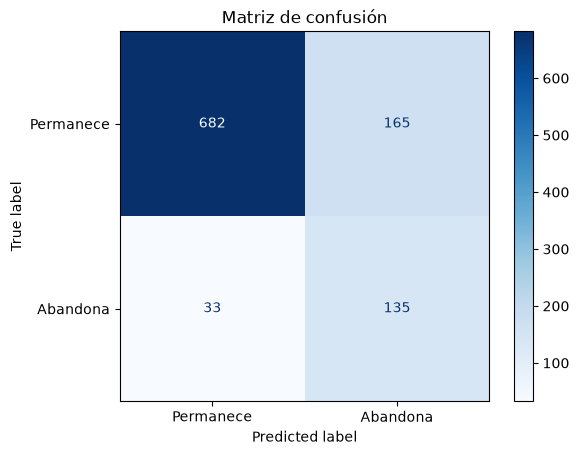

In [179]:
# Reporte por clase
print(classification_report(y_test, y_pred_base, target_names=["Permanece", "Abandona"]))

# Matriz de confusion
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred_base, display_labels=["Permanece", "Abandona"], cmap="Blues"
)
plt.title("Matriz de confusión")
plt.grid(False)
plt.show()

### Conclusiones de la evaluación

**Desempeño.** El modelo base supera ampliamente al clasificador de control: alcanza un ROC-AUC de 0.884 (frente a 0.5 del azar), detecta al 80% de los clientes que abandonan (recall = 0.80) y lo hace sin sobreajuste con un ROC-AUC de 0.904 en entrenamiento y 0.884 en prueba. Su precision es de 0.45 que representa qu menos de la mitad de las alertas es realmente un abandono real.

**Limitaciones**

* **Evaluación con una sola división de los datos**. Las métricas se calcularon a partir de una única partición de entrenamiento y prueba, unicaménte 168 casos de abandono en el conjunto de prueba. Por ello, los resultados pueden variar con otra división de los datos.
* **Umbral y configuración del modelo**. Se mantuvo el umbral de 0.5 por defecto  ademas de que no se realizó un  ajuste de hiperparámetrso.
* **Alcance del modelo**. Como trabajamos con una regresión logística, el modelo tiene complicaciones para identificar relaciones más complejas entre las variables, como en el caso donde una depende de otra. 

### 6. Registro de experimento en MLFlow

In [185]:
mlflow.set_tracking_uri("http://127.0.0.1:5000")
mlflow.set_experiment("churn-ecommerce-baseline")

parametros = {
    "modelo": "LogisticRegression",
    "class_weight": "balanced",
    "C": 1.0,
    "penalty": "l2",
    "solver": "lbfgs",
    "max_iter": 1000,
    "imputacion": "mediana",
    "indicadores_faltante": True,
    "escalado": "StandardScaler",
    "codificacion": "OneHotEncoder(handle_unknown=ignore)",
    "test_size": 0.2,          
    "estratificado": True,
    "seed": SEED,
    "n_train": X_train.shape[0],
    "n_test": X_test.shape[0],
    "n_variables_modelo": n_vars,
}

# Métricas sobre el conjunto de prueba 
metricas = {
    "accuracy": accuracy_score(y_test, y_pred_base),
    "precision": precision_score(y_test, y_pred_base),
    "recall": recall_score(y_test, y_pred_base),
    "f1": f1_score(y_test, y_pred_base),
    "roc_auc": roc_auc_score(y_test, y_prob_base),
    "roc_auc_train": auc_train,
}

with mlflow.start_run(run_name="regresion_logistica_baseline"):

    # Etiquetas del run
    mlflow.set_tags({
        "dataset": "E-commerce Customer Churn (Kaggle)",
        "tarea": "clasificacion binaria - churn",
        "etapa": "baseline",
    })

    # Parametros y métricas
    mlflow.log_params(parametros)
    mlflow.log_metrics(metricas)

    # Signature
    signature = infer_signature(X_train, modelo_baseline.predict(X_train))

    # Modelo: Pipeline completo, con ejemplo de entrada y registro en el Model Registry
    model_info = mlflow.sklearn.log_model(
        sk_model=modelo_baseline,
        name="modelo",                       
        signature=signature,
        input_example=X_train.head(5),
        registered_model_name="churn-ecommerce-baseline",
        skops_trusted_types=["numpy.dtype"],
    )

    # Tags del modelo
    mlflow.set_logged_model_tags(
        model_info.model_id,
        {"descripcion": "Regresion logistica baseline con preprocesamiento en Pipeline"},
    )
print("Run registrado correctamente")

/Users/denissemartinez/prjs/mlops/venv_mlops/lib/python3.14/site-packages/mlflow/types/utils.py:440: UserWarning: Hint: Inferred schema contains integer column(s). Integer columns in Python cannot represent missing values. If your input data contains missing values at inference time, it will be encoded as floats and will cause a schema enforcement error. The best way to avoid this problem is to infer the model schema based on a realistic data sample (training dataset) that includes missing values. Alternatively, you can declare integer columns as doubles (float64) whenever these columns may have missing values. See `Handling Integers With Missing Values <https://www.mlflow.org/docs/latest/models.html#handling-integers-with-missing-values>`_ for more details.
  warnings.warn(
Successfully registered model 'churn-ecommerce-baseline'.
2026/10/04 20:34:34 INFO mlflow.store.model_registry.abstract_store: Waiting up to 300 seconds for model version to finish creation. Model name: churn-ecomm

🏃 View run regresion_logistica_baseline at: http://127.0.0.1:5000/#/experiments/3/runs/a697040bfb2a4f0b9910b56471a90c31
🧪 View experiment at: http://127.0.0.1:5000/#/experiments/3
Run registrado correctamente


Created version '1' of model 'churn-ecommerce-baseline'.


#### 6.1 Evidencia del registro en MLflow UI

El run `regresion_logistica_baseline` quedó registrado en el experimento `churn-ecommerce-baseline`. Se observan los **parámetros** (configuración del modelo, imputación, escalado, codificación, semilla y tamaños de train/test) y las **métricas** sobre el conjunto de prueba (accuracy, precision, recall, F1 y ROC-AUC), junto con el ROC-AUC de entrenamiento.

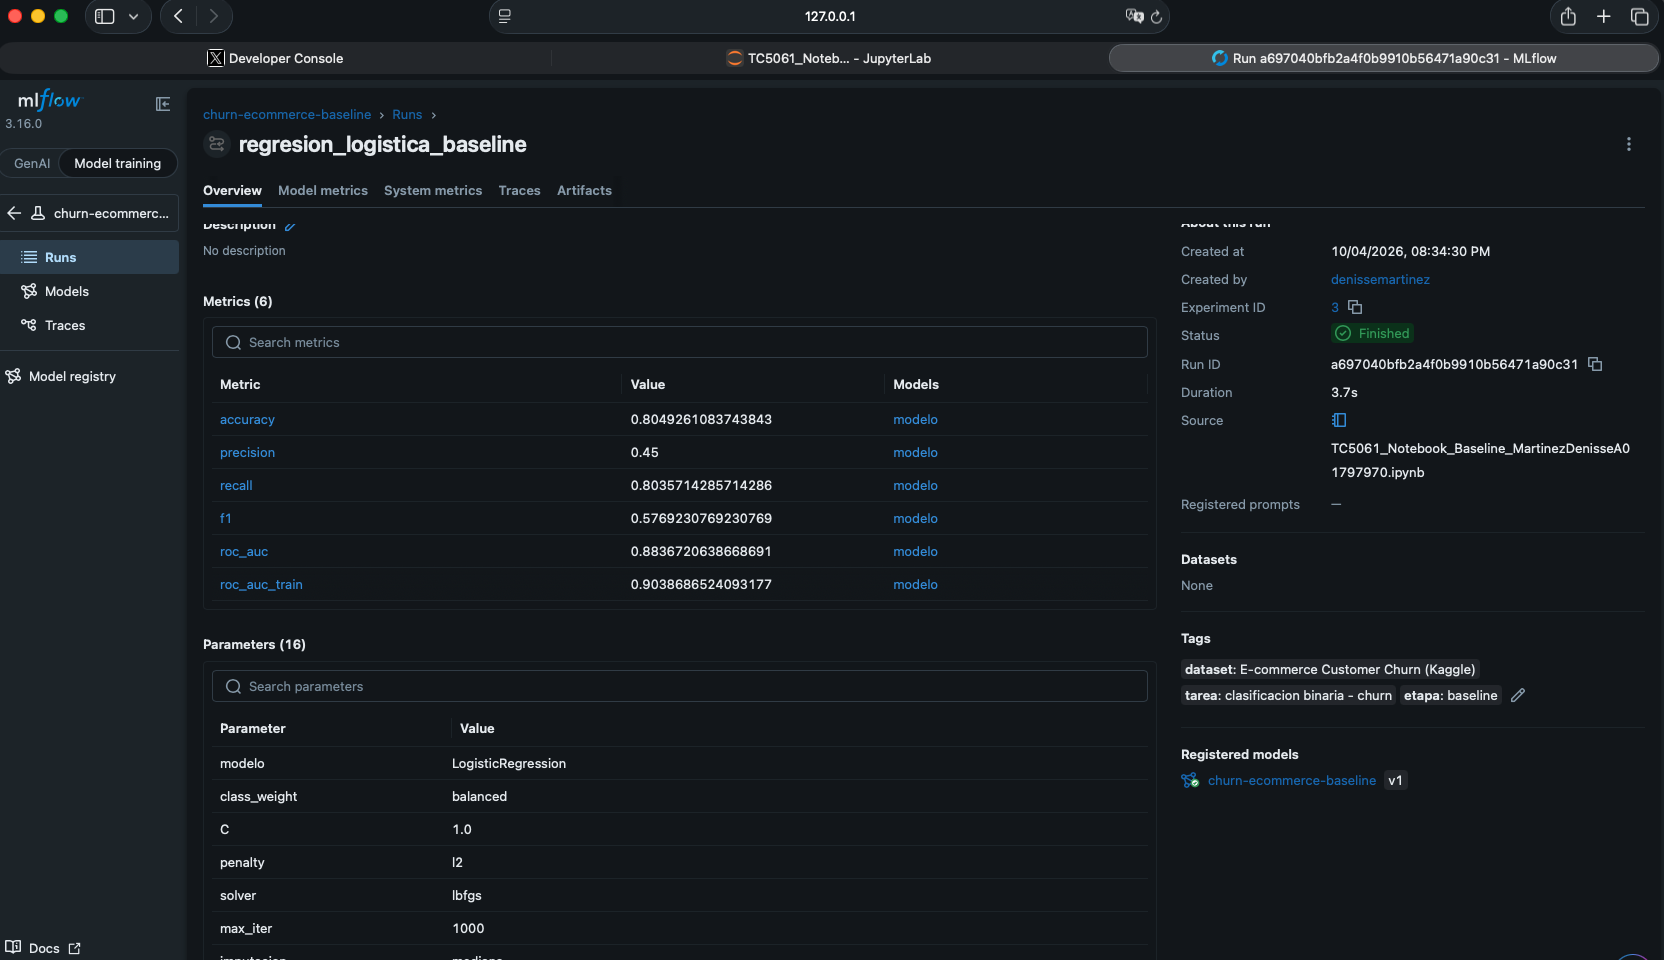


### 7. Reflexión sobre MLFlow

Lo que más tiempo me llevó en este ejercicio no fue construir el modelo, sino preparar los datos. El EDA y la limpieza me hicieron detenerme en situaciones que no eran tan evidentes al principio. Por ejemplo, encontré 556 registros duplicados que no se detectaban a simple vista porque el `CustomerID` era diferente, además de tener que analizar cómo tratar los valores nulos y los valores atípicos. Aunque es una parte menos visible del trabajo, este ejercicio me hizo reafirmar que las decisiones que se toman en esta etapa terminan teniendo un impacto directo en el modelo, por lo que es importante poder explicar por qué se tomó cada una.

También pude relacionar este ejercicio con algo que veo constantemente en mi trabajo como ingeniera de datos: una solución no solo debe funcionar, también debe poder mantenerse y evolucionar. Por eso, MLflow me pareció especialmente útil. En experiencias anteriores, al modificar parámetros o probar diferentes versiones, era fácil perder de vista qué había cambiado y cuál había sido el resultado anterior. Tener registrados los parámetros, las métricas y el modelo en cada *run* permite conservar ese historial. Además, al tratarse de un *baseline*, el primer modelo se convierte en un punto de referencia para saber si los cambios que hagamos realmente representan una mejora.

Otro aprendizaje importante para mí fue la diferencia entre trazabilidad y explicabilidad. MLflow permite saber qué configuración y qué datos dieron origen a un resultado, mientras que la explicabilidad busca entender por qué el modelo tomó una determinada decisión. No son lo mismo, pero considero que se complementan y que ambas son importantes cuando los resultados de un modelo deben comunicarse al negocio o revisarse desde áreas de gobierno de datos.

A partir de este ejercicio, también veo algunas mejoras que podría incorporar. Por ejemplo, llevar un control de la versión de los datos, quizá registrando el *hash* del archivo en cada *run*, para saber exactamente con qué información se entrenó cada modelo. También probaría validación cruzada estratificada y compararía diferentes configuraciones, como utilizar o no los indicadores de valores faltantes. Si en algún momento el modelo llegara a producción, sería necesario darle seguimiento para identificar cambios en los datos o en su desempeño y saber cuándo sería necesario ajustarlo o volver a entrenarlo.
